# Lab 1 – Fashion-MNIST Image Classification with an MLP 

**Course:** Machine Learning
**Dataset:** Fashion-MNIST
**Model:** MLP (Multi-Layer Perceptron)
**Each experiment:** trained for the full **30 epochs**
**Code style:** object-oriented. All classes live in the `src/` package (one file per module, documented in `docs/`). This notebook only imports them and runs the workflow, so each experiment is just one `ExperimentConfig` object.

## Objectives
- Explore and visualise the Fashion-MNIST dataset.
- Build a flexible MLP: number of hidden layers, width, Dropout, activation function, BatchNorm.
- Run **15 experiments** in 7 groups, 30 epochs each, changing only one factor at a time compared with the baseline.
- Compare experiments using Accuracy, Macro Precision, Macro Recall, Macro F1-score, learning curves, the Train – Evaluation gap and per-class accuracy.
- Analyse the baseline and the best model in detail with confusion matrices and sample predictions.

## Experiment groups
| Group | Factor changed | Experiments |
|---|---|---|
| 1 | Number of hidden layers | 1 layer (256) • **2 layers (256-128) – baseline** • 3 layers (256-128-64) |
| 2 | Hidden layer width | 64-32 • 512-256 |
| 3 | Dropout | 0.0 • 0.5 |
| 4 | Activation function | Tanh • GELU |
| 5 | Optimizer and learning rate | Adam 0.0001 • Adam 0.01 • SGD 0.01 + momentum 0.9 |
| 6 | BatchNorm | With BatchNorm |
| 7 | Batch size | 32 • 256 |

Baseline: 784 → 256 → 128 → 10, ReLU, Dropout 0.2 after every hidden layer, Adam lr 0.001, batch size 64. All experiments use the **same seed** for weight initialisation and data shuffling so the comparison is fair.

## Companion notebooks: increasing sweeps
Three extra notebooks each increase **one** factor step by step and compare every step side by side. They can be run on their own, in any order:

| Notebook | Factor increased | Steps (bold = baseline) |
|---|---|---|
| `Lab1_Sweep_HiddenLayers.ipynb` | Number of hidden layers | 1 → **2** → 3 → 4 → 5 |
| `Lab1_Sweep_LearningRate.ipynb` | Learning rate (Adam) | 0.0001 → 0.0005 → **0.001** → 0.005 → 0.01 → 0.05 |
| `Lab1_Sweep_BatchSize.ipynb` | Batch size | 16 → 32 → **64** → 128 → 256 → 512 |

## Module map
| Module | Contents | Documentation |
|---|---|---|
| `src/utils.py` | `SEED`, `DEVICE`, class names, `set_seed`, `slugify` | `docs/utils.md` |
| `src/config.py` | `ExperimentConfig`, `configs_to_dataframe` | `docs/config.md` |
| `src/model.py` | `MLP`, `ACTIVATIONS` | `docs/model.md` |
| `src/data.py` | `FashionMNISTData` | `docs/data.md` |
| `src/explorer.py` | `DatasetExplorer` | `docs/explorer.md` |
| `src/trainer.py` | `Trainer` | `docs/trainer.md` |
| `src/evaluator.py` | `Evaluator` | `docs/evaluator.md` |
| `src/runner.py` | `ExperimentResult`, `ExperimentRunner` | `docs/runner.md` |
| `src/experiments.py` | `BASELINE`, `build_experiments`, `select_experiments` | `docs/experiments.md` |

## 1. Imports, device and seed
Everything comes from the `src` package. `set_seed` fixes all random sources so every experiment can be re-run with the same result. The notebook uses a GPU automatically when one is available.

The `%autoreload` lines make Jupyter pick up any edit you make to a file in `src/` without restarting the kernel.

In [1]:
%load_ext autoreload
%autoreload 2

# Tim thu muc du an de Python nhan dien duoc package src khi mo notebook tu Colab/Jupyter.
from pathlib import Path
import sys

_project_candidates = [Path.cwd(), *Path.cwd().parents]
_project_candidates += [p for p in Path.cwd().glob("*/") if p.is_dir()]
_project_root = next(
    (p.resolve() for p in _project_candidates if (p / "src" / "__init__.py").is_file()),
    None,
)
if _project_root is None:
    raise FileNotFoundError(
        "Khong tim thay thu muc src. Hay mo notebook trong "
        "Lab1_FashionMNIST_MLP_OOP hoac giai nen day du file ZIP."
    )
if str(_project_root) not in sys.path:
    sys.path.insert(0, str(_project_root))

import pandas as pd
import torch
from IPython.display import display

from src import (
    SEED, DEVICE, CLASS_NAMES, CORE_GROUPS, set_seed,
    ExperimentConfig, configs_to_dataframe,
    MLP, FashionMNISTData, DatasetExplorer,
    Evaluator, ExperimentRunner,
    BASELINE, select_experiments,slugify
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

set_seed(SEED)
print("Thiết bị huấn luyện:", DEVICE)
print("Phiên bản PyTorch:", torch.__version__)

Thiết bị huấn luyện: cuda
Phiên bản PyTorch: 2.5.1+cu121


## 2. `ExperimentConfig` – describing one experiment
Defined in `src/config.py` (see `docs/config.md`). An `ExperimentConfig` holds every hyperparameter of one experiment: the architecture (`hidden_sizes`, `activation`, `dropout`, `batch_norm`) and the training setup (`optimizer`, `lr`, `momentum`, `batch_size`, `epochs`, `seed`). The fields not passed in take the baseline values.

In [2]:
baseline_cfg = ExperimentConfig(name="demo", group="demo")
print(baseline_cfg)
print("Kiến trúc:", baseline_cfg.architecture)
print("Optimizer:", baseline_cfg.optimizer_text)

ExperimentConfig(name='demo', group='demo', hidden_sizes=(256, 128), activation='relu', dropout=0.2, batch_norm=False, optimizer='adam', lr=0.001, momentum=0.9, batch_size=64, epochs=30, seed=42)
Kiến trúc: 784 -> 256 -> 128 -> 10
Optimizer: Adam (lr=0.001)


## 3. `MLP` – the multi-layer perceptron
Defined in `src/model.py` (see `docs/model.md`). `MLP` takes an `ExperimentConfig` and builds its layers: each hidden layer is `Linear` → (`BatchNorm1d` if enabled) → activation → (`Dropout` if > 0). The last layer is a `Linear` with 10 outputs, one per class. The 28 × 28 image is flattened into a 784-dimensional vector at the start of the network.

In [3]:
# Quick check: print the structure of the baseline model
_demo = MLP(baseline_cfg)
print(_demo)
print(f"\nTổng số tham số: {_demo.count_parameters():,}")
del _demo

MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.2, inplace=False)
    (7): Linear(in_features=128, out_features=10, bias=True)
  )
)

Tổng số tham số: 235,146


## 4. Exploratory Data Analysis
Data: `FashionMNISTData` and `DatasetExplorer`
- `FashionMNISTData` (`src/data.py`, see `docs/data.md`) downloads Fashion-MNIST, keeps the raw data (integers 0–255) for exploration and converts it to tensors in [0, 1] for training (equivalent to `ToTensor()`). All images are loaded into memory once and the `DataLoader` slices whole batches (64 images for training, 512 for testing), so each epoch is much faster than decoding PIL images one by one. `get_loaders` uses a seeded random generator so the shuffle order is reproducible.
- `DatasetExplorer` (`src/explorer.py`, see `docs/explorer.md`) groups the visualisation functions: overview, class distribution, sample images, mean images and pixel values.

### 4.1. Load the data and show an overview

In [4]:
data = FashionMNISTData(root="./data")
explorer = DatasetExplorer(data)
explorer.overview()

,Thông tin,Giá trị
0,Số ảnh huấn luyện,"60,000"
1,Số ảnh kiểm tra,"10,000"
2,Kích thước mỗi ảnh (pixel),28 x 28
3,Số kênh màu,1 (ảnh xám)
4,Số lớp,10
5,Kiểu dữ liệu gốc,uint8
6,Khoảng giá trị pixel gốc,0 - 255
7,Khoảng giá trị sau khi chuẩn hóa,0.0 - 1.0
8,Kích thước tensor một ảnh,"(1, 28, 28)"


,Nhãn,Tên lớp (English),Tên lớp (Tiếng Việt)
0,0,T-shirt/top,Áo thun
1,1,Trouser,Quần dài
2,2,Pullover,Áo len chui đầu
3,3,Dress,Váy
4,4,Coat,Áo khoác
5,5,Sandal,Dép xăng-đan
6,6,Shirt,Áo sơ mi
7,7,Sneaker,Giày thể thao
8,8,Bag,Túi xách
9,9,Ankle boot,Bốt cổ thấp


### 4.2. Number of images per class
This chart shows whether the classes are balanced.

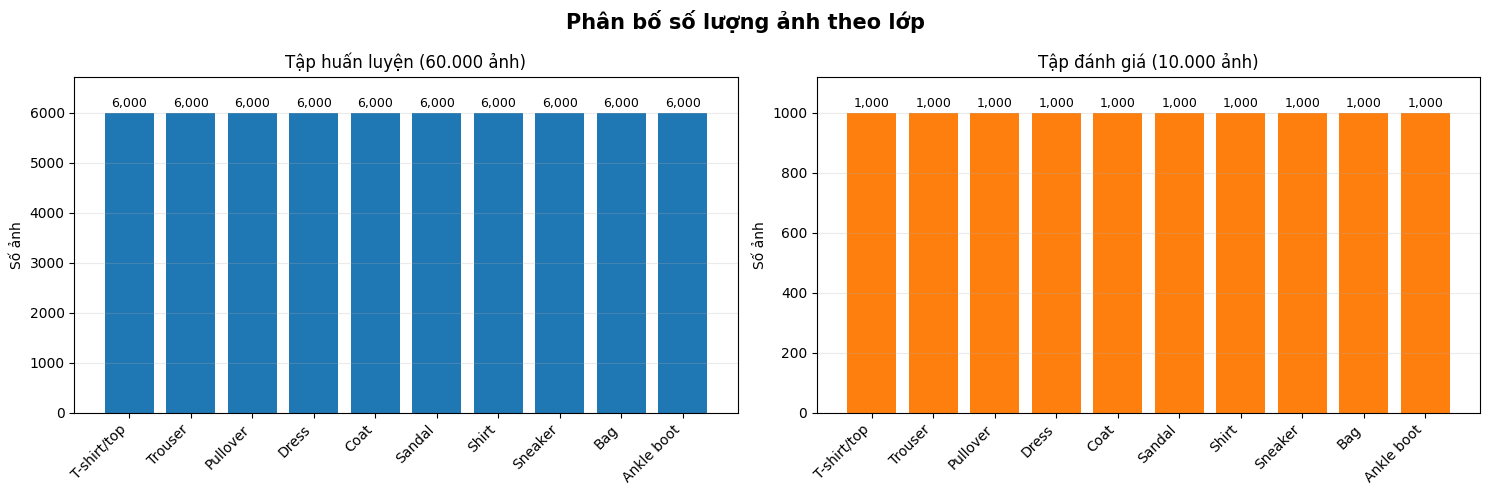

In [5]:
explorer.plot_distribution()

### 4.3. Sample images of each class
Each row is one class and shows the first 10 images of that class in the training set.

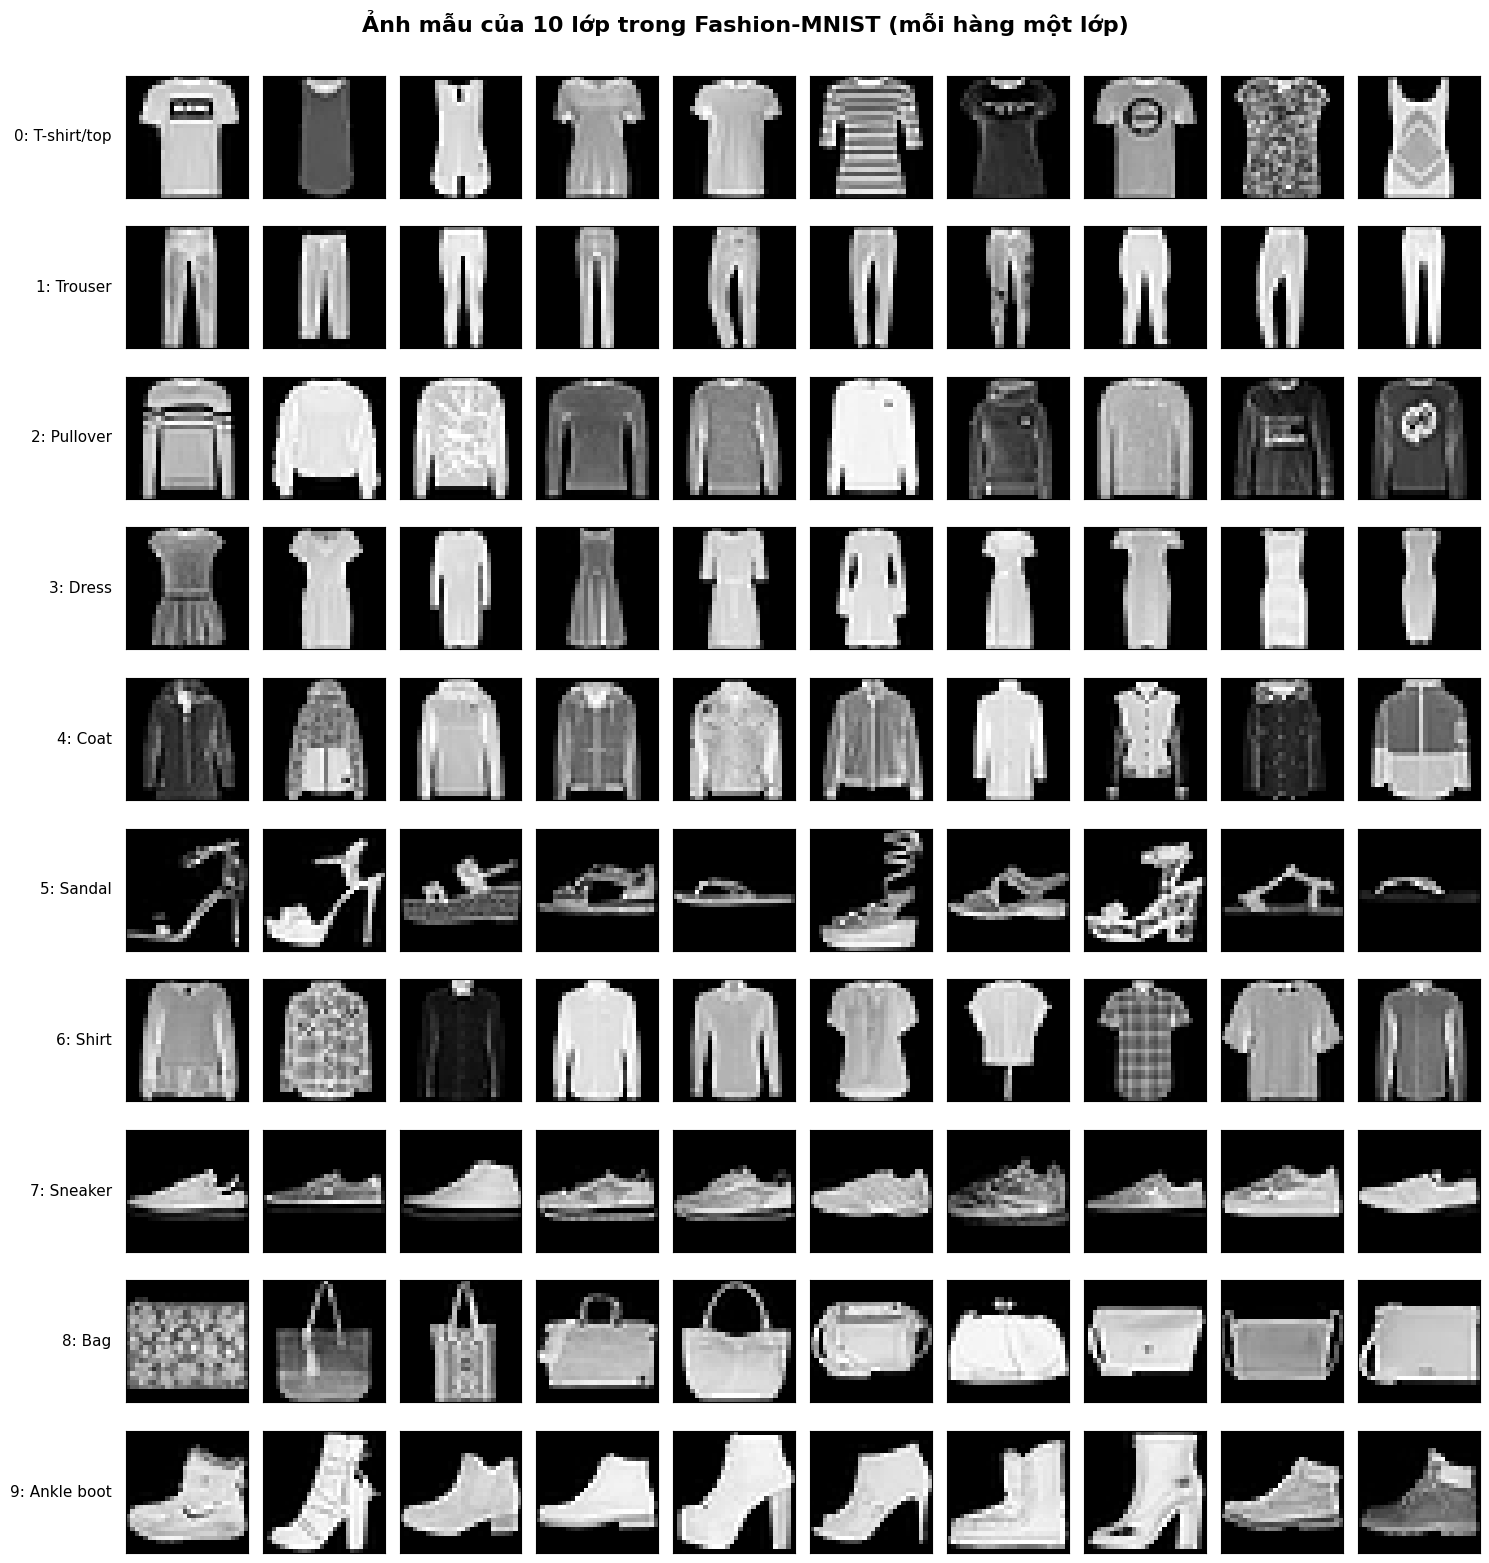

In [6]:
explorer.plot_samples(n_per_class=10)

### 4.4. Mean image of each class
Classes with similar mean images (for example Shirt, T-shirt/top, Pullover and Coat) are usually the ones the model confuses most.

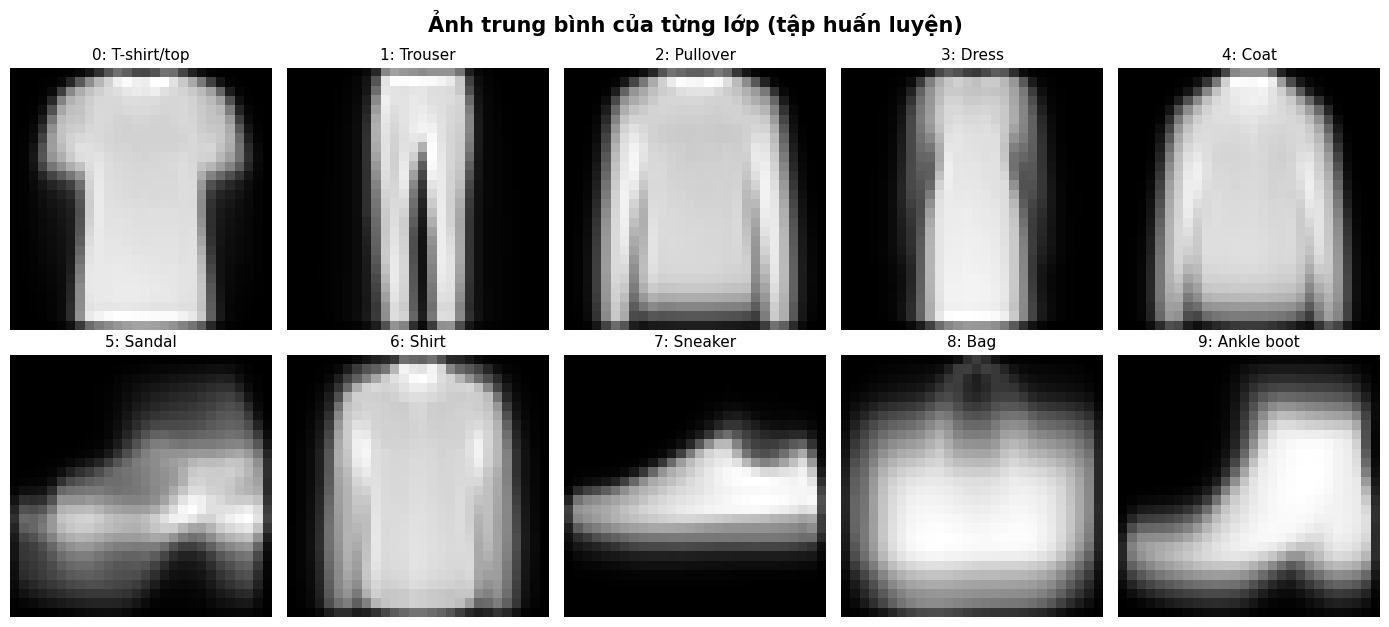

In [7]:
explorer.plot_mean_images()

### 4.5. Pixel values of one image
Each image is a 28 × 28 matrix of values from 0 (black) to 255 (white).

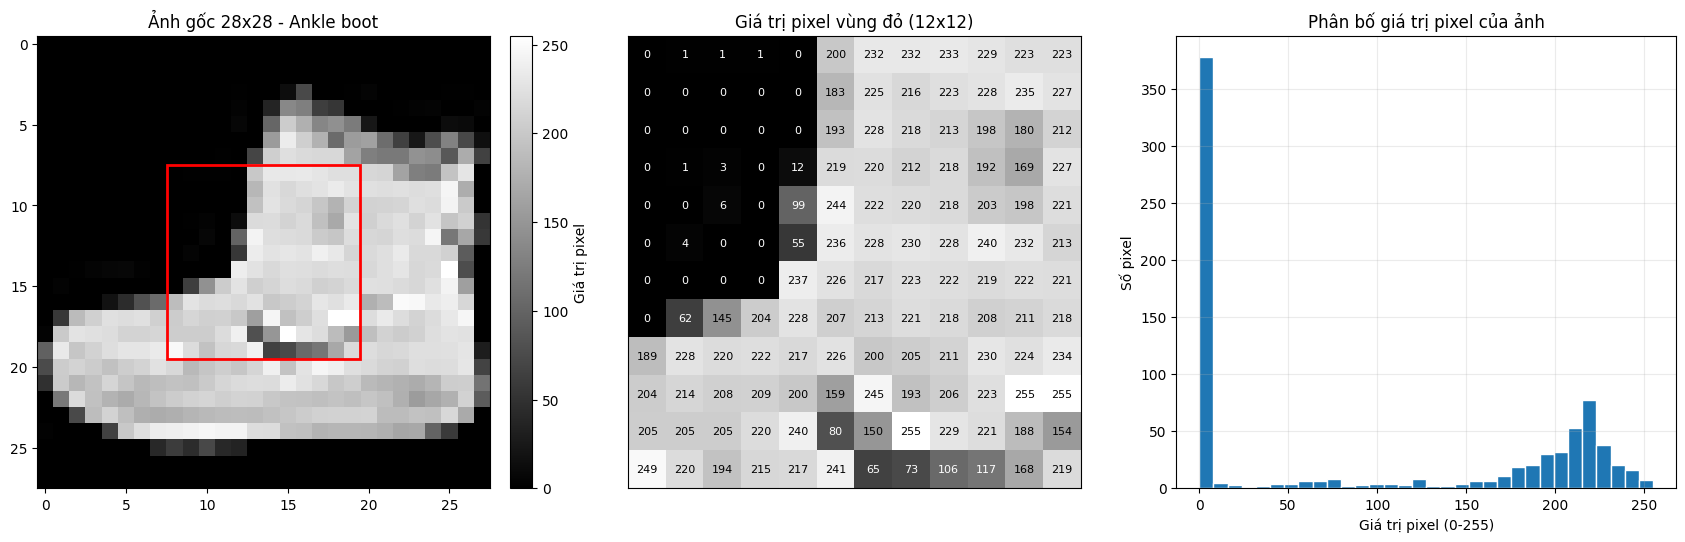

Pixel nhỏ nhất: 0, lớn nhất: 255, trung bình: 97.25
Tỉ lệ pixel nền (giá trị 0): 44.8%


In [8]:
explorer.plot_pixel_values(index=0)

### 4.5. Transform

Train batch: (64, 1, 28, 28) | Eval batch: (512, 1, 28, 28)
Train pixel range: [-0.81, 2.02] | mean=0.008


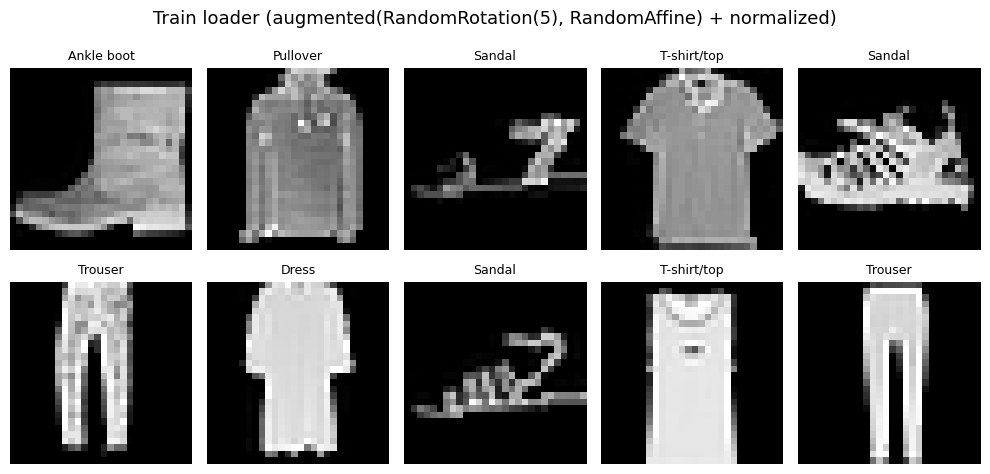

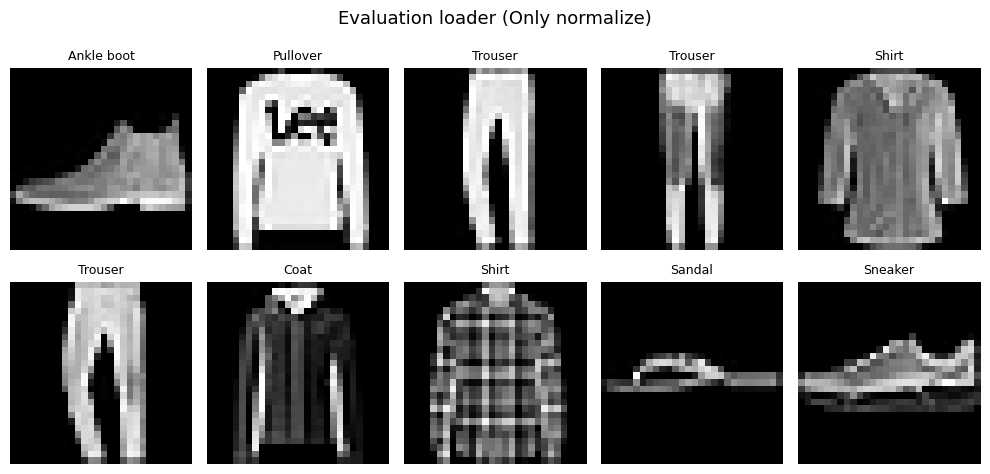

In [9]:
import matplotlib.pyplot as plt
import torch

# Đổi đường dẫn import cho đúng với cấu trúc project của bạn
from src.data import FashionMNISTData, MEAN, STD   # ví dụ: from src.data import ...

SEED = 42
BATCH_SIZE = 64
N_SHOW = 10

torch.manual_seed(SEED)  # để các phép augment ngẫu nhiên lặp lại được

data = FashionMNISTData(root="./data")
train_loader, evaluation_loader = data.get_loaders(batch_size=BATCH_SIZE, seed=SEED)

# Mỗi lần lặp loader trả về 1 batch (x, y) vì DataLoader dùng batch_size=None
x_train, y_train = next(iter(train_loader))
x_eval, y_eval = next(iter(evaluation_loader))
print("Train batch:", tuple(x_train.shape), "| Eval batch:", tuple(x_eval.shape))
print(f"Train pixel range: [{x_train.min():.2f}, {x_train.max():.2f}] | mean={x_train.mean():.3f}")


def denormalize(x):
    """Đưa ảnh đã Normalize về lại [0, 1] để hiển thị."""
    return (x * STD + MEAN).clamp(0, 1)


def show_images(images, labels, title, n=N_SHOW):
    fig, axes = plt.subplots(2, n // 2, figsize=(2 * (n // 2), 5))
    for ax, img, lbl in zip(axes.flat, images[:n], labels[:n]):
        ax.imshow(denormalize(img).squeeze(0), cmap="gray", vmin=0, vmax=1)
        ax.set_title(data.class_names[lbl.item()], fontsize=9)
        ax.axis("off")
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()


show_images(x_train, y_train, "Train loader (augmented(RandomRotation(5), RandomAffine) + normalized)")
show_images(x_eval, y_eval, "Evaluation loader (Only normalize)")

## 5. `Trainer` and `Evaluator`
- `Trainer` (`src/trainer.py`, see `docs/trainer.md`) handles training: it builds the optimizer from the config, runs each epoch, records the train and evaluation Loss/Accuracy and predicts on a `DataLoader`. Train accuracy is measured during training (Dropout is active), while evaluation accuracy is measured in evaluation mode.
- `Evaluator` (`src/evaluator.py`, see `docs/evaluator.md`) handles evaluation and plotting: macro metrics, per-class accuracy, learning curves, confusion matrices and correct/wrong sample predictions.

Both are used inside `ExperimentRunner`, so they are not called directly here.

## 6. `ExperimentResult` and `ExperimentRunner`
Defined in `src/runner.py` (see `docs/runner.md`).
- `ExperimentResult` stores everything about one experiment: config, training history, metrics, evaluation predictions, number of parameters, training time and the path of the weight file.
- `ExperimentRunner` runs the configs one after another (same seed, same data), saves each model's weights to `saved_models/`, then builds the summary tables, per-group comparison plots, overall plots, detailed analysis and the automatic summary.

## 7. Experiment list
The experiments are declared in `src/experiments.py` (see `docs/experiments.md`). Each one changes **one** factor compared with the baseline. You can change `EPOCHS` or pick a few groups in `SELECTED_GROUPS` for a quick evaluation run (`CORE_GROUPS` runs the 15 experiments of groups 1–7; the baseline is always included). Groups 8–10 are run by the sweep notebooks. The assignment requires 30 epochs, so `EPOCHS = 30`.

In [10]:
from typing import List


EPOCHS = 35
TEST_EPOCHS = 1

SELECTED_GROUPS = CORE_GROUPS   # groups 1-7; e.g. ["1. Số lớp ẩn", "3. Dropout"] to run only these groups
LOG_EVERY = 5               # print every 5 epochs; set to 1 to see every epoch

TEST_GROUPS = BASELINE

experiments = select_experiments(epochs=EPOCHS, groups=SELECTED_GROUPS)
print(f"Số thí nghiệm sẽ chạy: {len(experiments)} (mỗi thí nghiệm {EPOCHS} epoch)")
display(configs_to_dataframe(experiments))

Số thí nghiệm sẽ chạy: 15 (mỗi thí nghiệm 35 epoch)


,Thí nghiệm,Nhóm,Kiến trúc,Activation,Dropout,BatchNorm,Optimizer,Batch size,Epoch
0,Cơ sở: 2 lớp ẩn (256-128),1. Số lớp ẩn,784 -> 256 -> 128 -> 10,relu,0.2,False,Adam (lr=0.001),64,35
1,1 lớp ẩn (256),1. Số lớp ẩn,784 -> 256 -> 10,relu,0.2,False,Adam (lr=0.001),64,35
2,3 lớp ẩn (256-128-64),1. Số lớp ẩn,784 -> 256 -> 128 -> 64 -> 10,relu,0.2,False,Adam (lr=0.001),64,35
3,Hẹp: 2 lớp ẩn (64-32),2. Độ rộng lớp ẩn,784 -> 64 -> 32 -> 10,relu,0.2,False,Adam (lr=0.001),64,35
4,Rộng: 2 lớp ẩn (512-256),2. Độ rộng lớp ẩn,784 -> 512 -> 256 -> 10,relu,0.2,False,Adam (lr=0.001),64,35
5,Dropout 0.0,3. Dropout,784 -> 256 -> 128 -> 10,relu,0.0,False,Adam (lr=0.001),64,35
6,Dropout 0.5,3. Dropout,784 -> 256 -> 128 -> 10,relu,0.5,False,Adam (lr=0.001),64,35
7,Activation Tanh,4. Hàm kích hoạt,784 -> 256 -> 128 -> 10,tanh,0.2,False,Adam (lr=0.001),64,35
8,Activation RELU,4. Hàm kích hoạt,784 -> 256 -> 128 -> 10,relu,0.2,False,Adam (lr=0.001),64,35
9,Adam lr=0.0001,5. Bộ tối ưu & learning rate,784 -> 256 -> 128 -> 10,relu,0.2,False,Adam (lr=0.0001),64,35


## 8. Run all experiments
Each experiment creates a new model, resets the seed and trains for the full 30 epochs. This is the slowest cell: usually a few minutes on a GPU, much longer on a CPU. The notebook prints results every `LOG_EVERY` epochs and saves each model's weights to `saved_models/`.

In [11]:
evaluator = Evaluator(CLASS_NAMES, data.evaluation_images)
runner = ExperimentRunner(data, evaluator, baseline_name=BASELINE, save_dir="./saved_models")
runner.run_all(experiments, log_every=LOG_EVERY)


[1/15]
===== Cơ sở: 2 lớp ẩn (256-128) | 784 -> 256 -> 128 -> 10 | Adam (lr=0.001) | batch 64 | 35 epochs =====
  [BEST] Epoch 01 | Evaluation Loss: 0.447885
  Epoch 01/35 | Train Loss: 0.6179 | Train Acc: 76.85% | Evaluation Loss: 0.4479 | Evaluation Acc: 83.29%
  [BEST] Epoch 02 | Evaluation Loss: 0.435936
  [BEST] Epoch 03 | Evaluation Loss: 0.397640
  [BEST] Epoch 04 | Evaluation Loss: 0.373079
  Epoch 05/35 | Train Loss: 0.4165 | Train Acc: 84.65% | Evaluation Loss: 0.3745 | Evaluation Acc: 86.53%
  [BEST] Epoch 06 | Evaluation Loss: 0.358134
  [BEST] Epoch 08 | Evaluation Loss: 0.346219
  Epoch 10/35 | Train Loss: 0.3826 | Train Acc: 85.81% | Evaluation Loss: 0.3483 | Evaluation Acc: 87.27%
  [BEST] Epoch 13 | Evaluation Loss: 0.341422
  [BEST] Epoch 14 | Evaluation Loss: 0.337705
  Epoch 15/35 | Train Loss: 0.3658 | Train Acc: 86.45% | Evaluation Loss: 0.3502 | Evaluation Acc: 86.93%
  [BEST] Epoch 16 | Evaluation Loss: 0.336519
  [BEST] Epoch 18 | Evaluation Loss: 0.334048
  [

## 9. Comparison within each group
Each figure shows Evaluation Accuracy, Evaluation Loss and Train Accuracy over 30 epochs. The black dashed line is the baseline, used as the reference in every group.

Figure saved: ./artifacts/saved_figures\group_curves\group_curves_1_so_lop_an.png


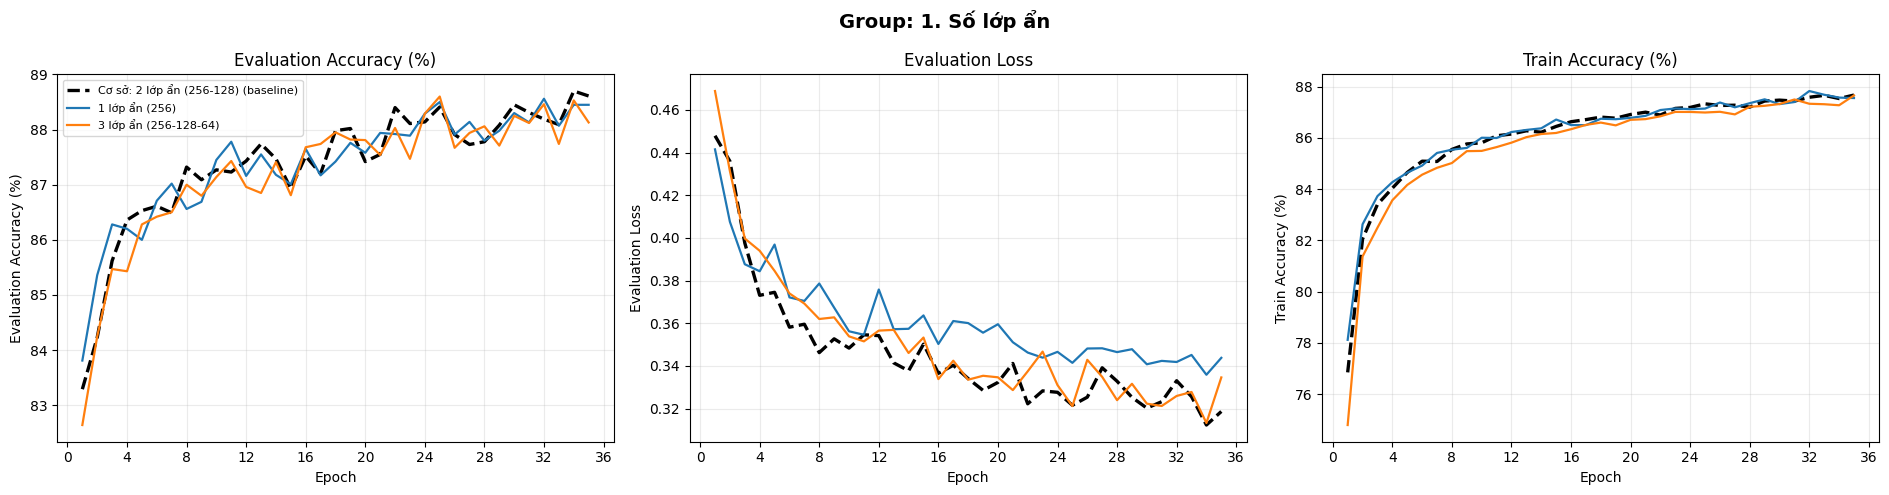

Figure saved: ./artifacts/saved_figures\group_curves\group_curves_2_do_rong_lop_an.png


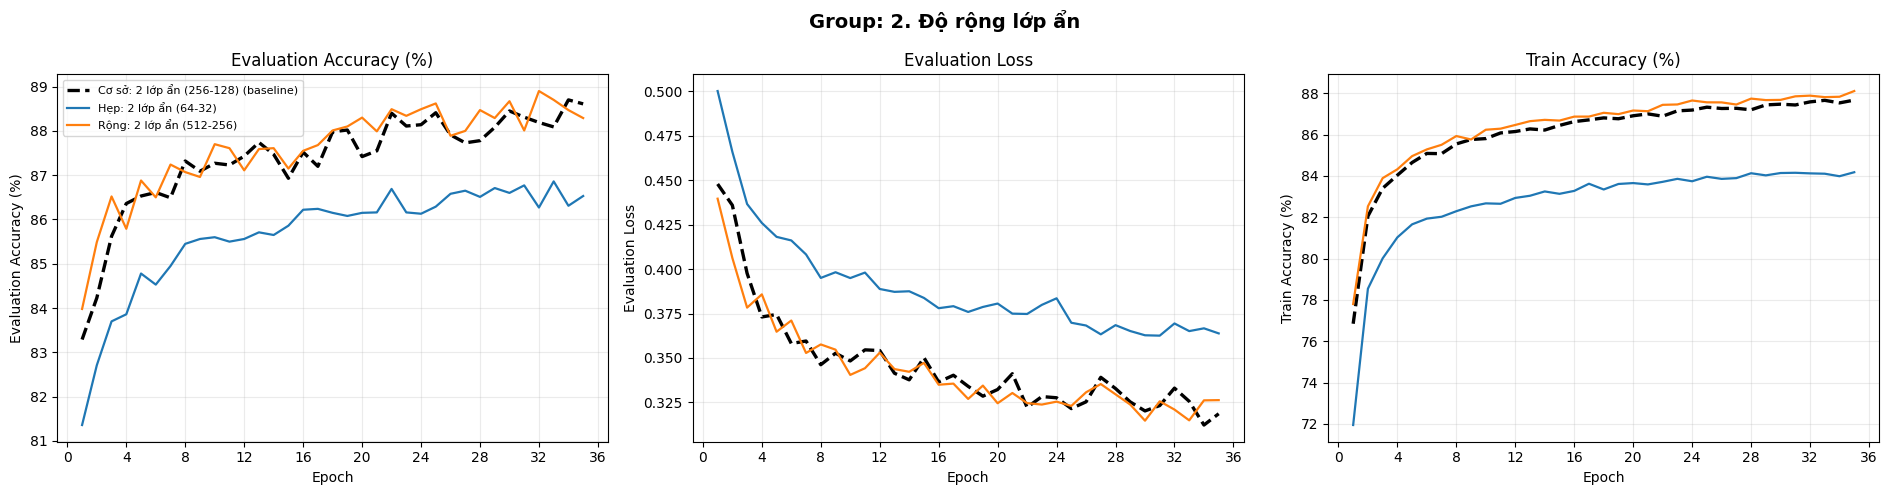

Figure saved: ./artifacts/saved_figures\group_curves\group_curves_3_dropout.png


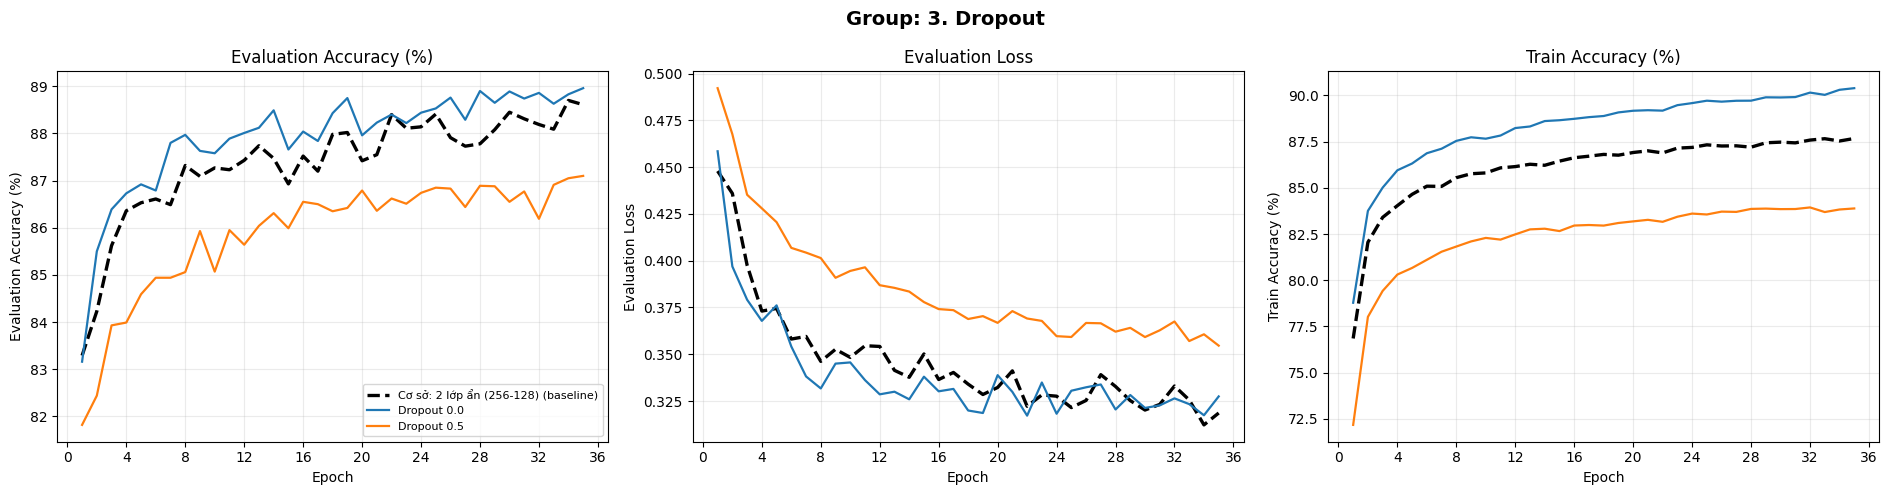

Figure saved: ./artifacts/saved_figures\group_curves\group_curves_4_ham_kich_hoat.png


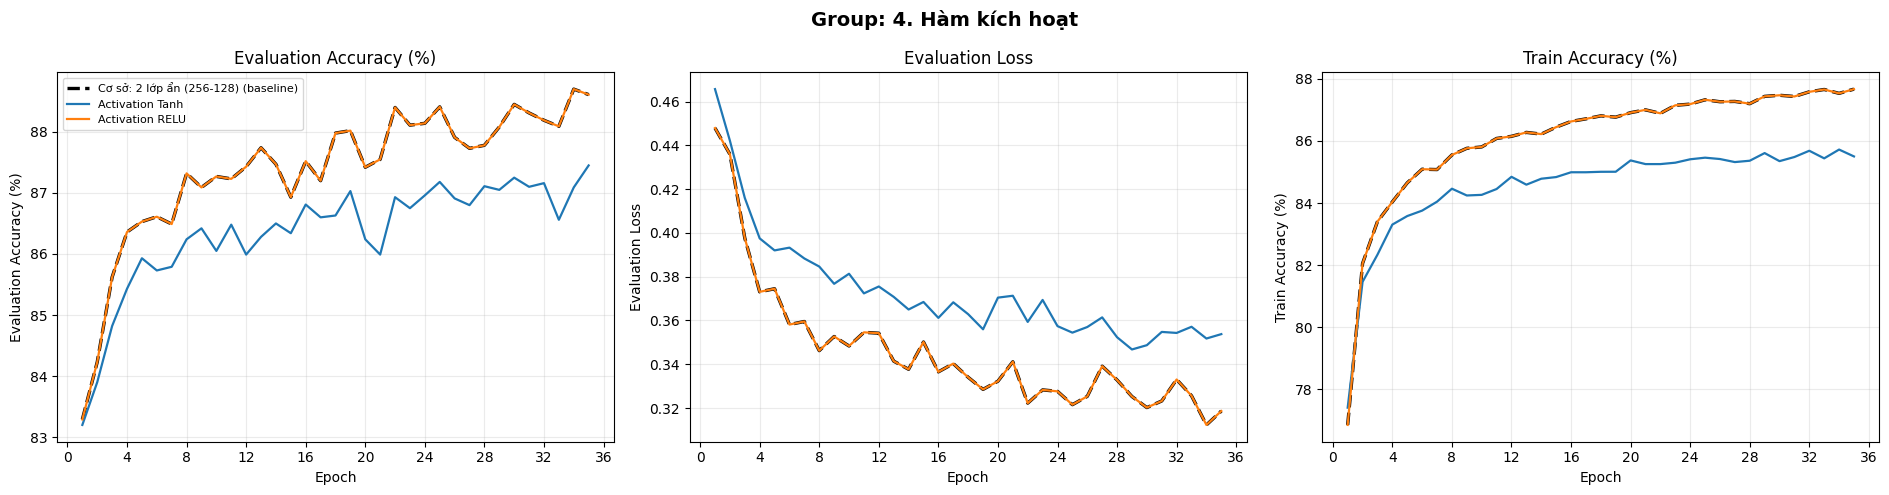

Figure saved: ./artifacts/saved_figures\group_curves\group_curves_5_bo_toi_uu_learning_rate.png


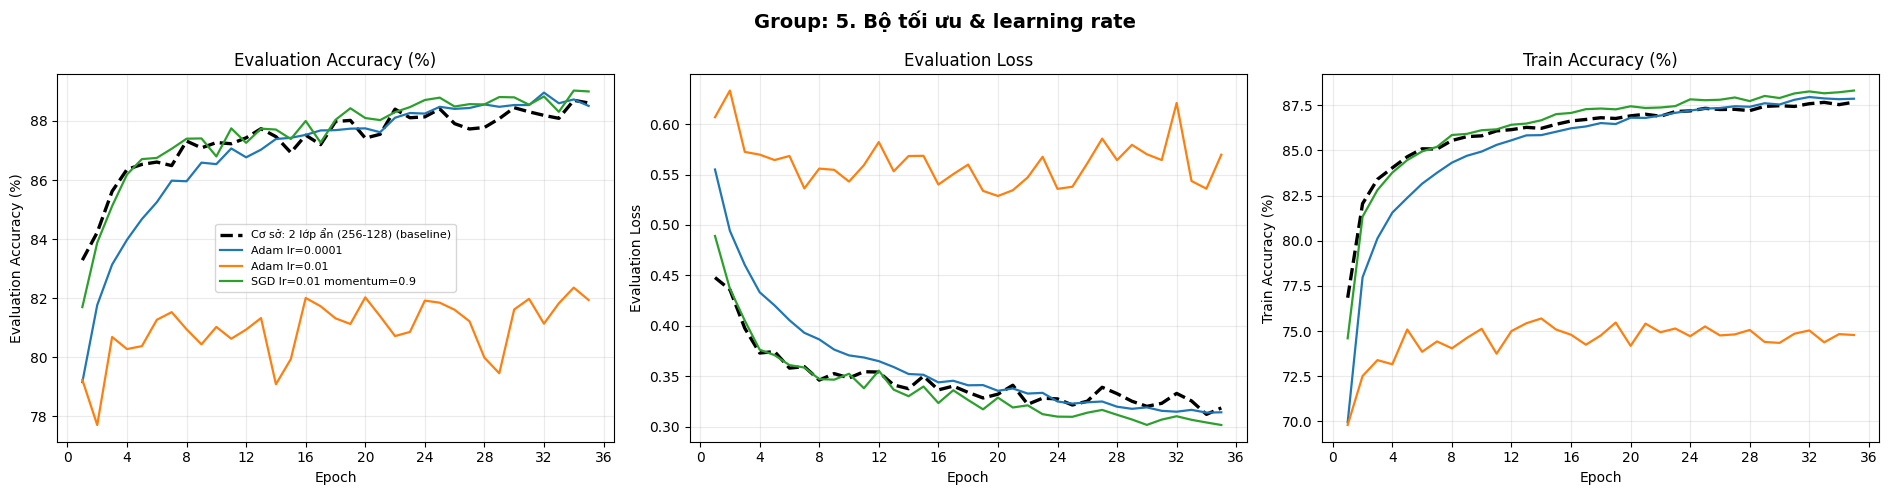

Figure saved: ./artifacts/saved_figures\group_curves\group_curves_6_batchnorm.png


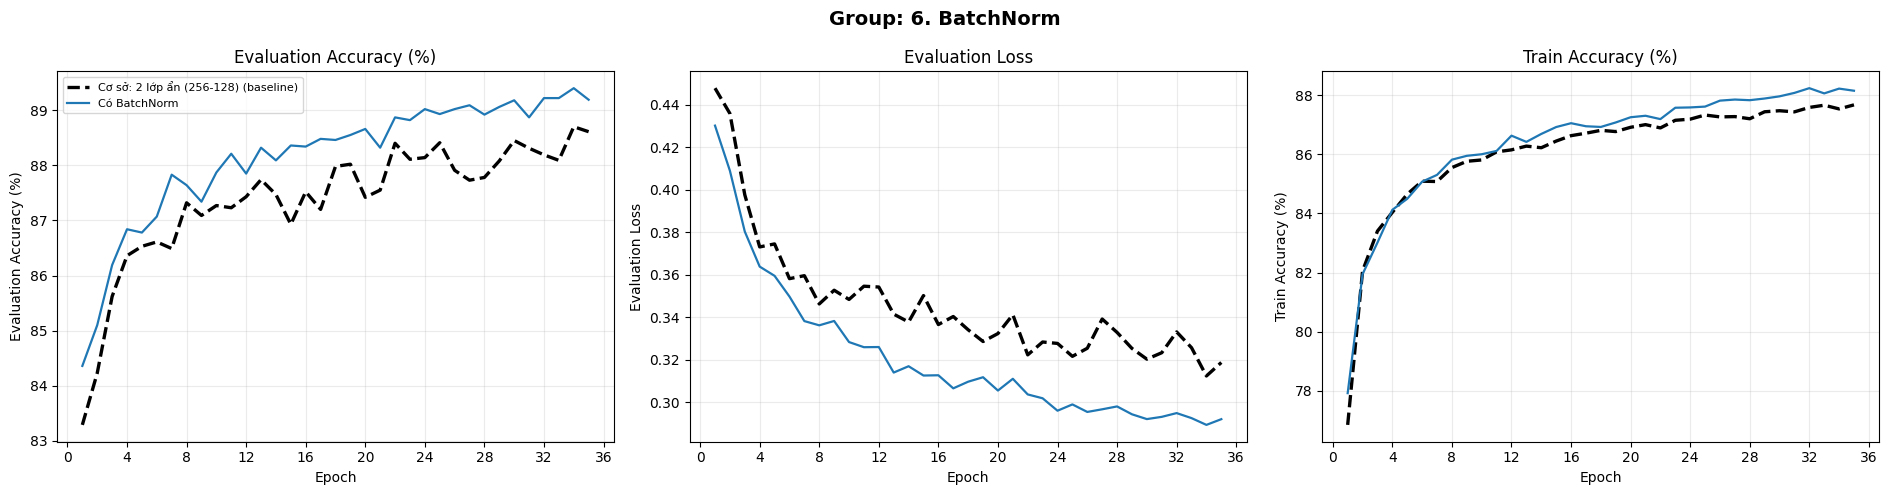

Figure saved: ./artifacts/saved_figures\group_curves\group_curves_7_batch_size.png


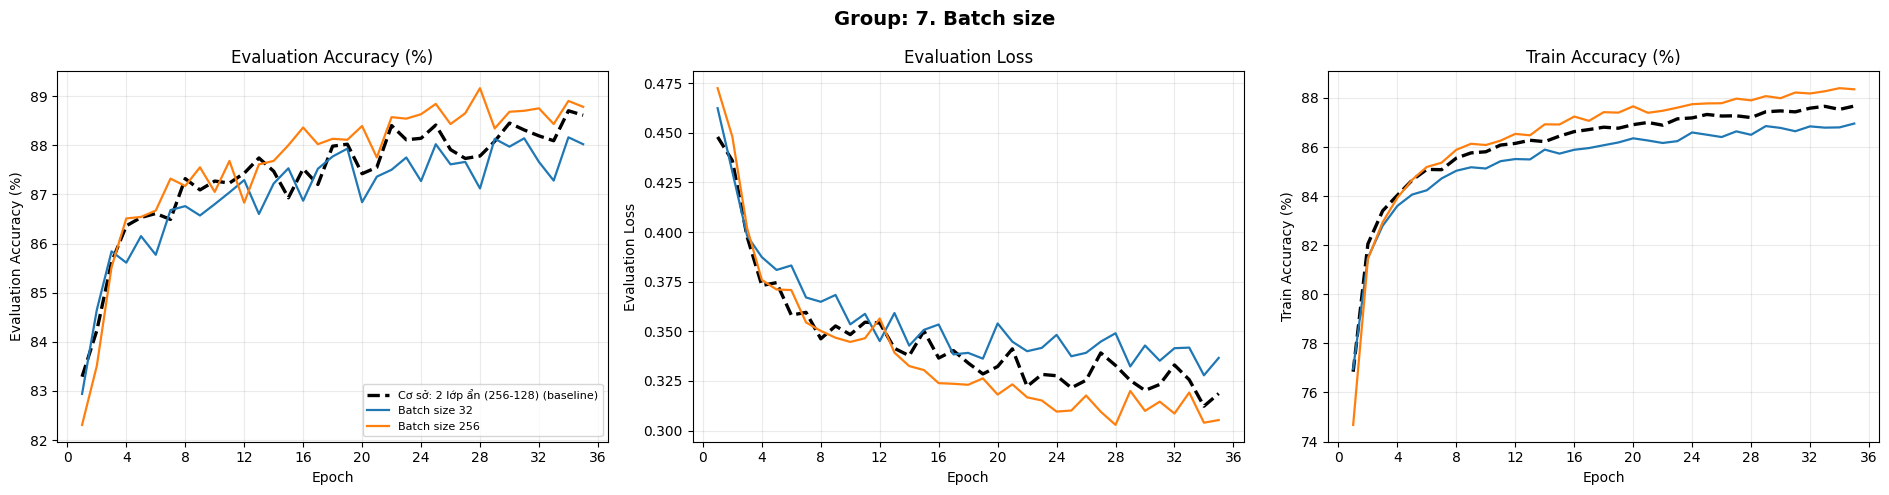

In [12]:
for group in runner.groups():
    runner.plot_group_curves(group)

## 10. Results summary
All metrics come from the model after the last epoch, computed on all 10,000 evaluation images. The *Chênh lệch Train-Evaluation* (Train – Evaluation gap) column is Train Accuracy minus Evaluation Accuracy: the larger it is, the stronger the sign of overfitting. The *Evaluation Acc cao nhất* (best evaluation accuracy) column is for reference only, because picking an epoch by the evaluation set is slightly optimistic; the main conclusions use the last epoch.

In [13]:
summary_df = runner.summary()
display(summary_df.round(4))


,Experiment,Group,Architecture,Parameters,Best Epoch,Best Evaluation Loss,Best Train Acc (%),Best Evaluation Acc (%),Best Train-Evaluation Gap,Macro Precision,Macro Recall,Macro F1-score,Last Epoch,Last Train Acc (%),Last Evaluation Acc (%),Last Evaluation Loss,Last Train-Evaluation Gap,Training Time (s)
0,Cơ sở: 2 lớp ẩn (256-128),1. Số lớp ẩn,784 -> 256 -> 128 -> 10,235146,34,0.3123,87.5350,88.70,-1.1650,0.8862,0.8870,0.8862,35,87.6717,88.61,0.3186,-0.9383,1436.5298
1,1 lớp ẩn (256),1. Số lớp ẩn,784 -> 256 -> 10,203530,34,0.3358,87.5717,88.45,-0.8783,0.8837,0.8845,0.8838,35,87.5550,88.45,0.3438,-0.8950,1490.4665
2,3 lớp ẩn (256-128-64),1. Số lớp ẩn,784 -> 256 -> 128 -> 64 -> 10,242762,34,0.3132,87.2733,88.53,-1.2567,0.8849,0.8853,0.8844,35,87.6567,88.13,0.3346,-0.4733,1498.1403
3,Hẹp: 2 lớp ẩn (64-32),2. Độ rộng lớp ẩn,784 -> 64 -> 32 -> 10,52650,31,0.3626,84.1533,86.77,-2.6167,0.8669,0.8677,0.8662,35,84.1800,86.53,0.3638,-2.3500,1491.2552
4,Rộng: 2 lớp ẩn (512-256),2. Độ rộng lớp ẩn,784 -> 512 -> 256 -> 10,535818,30,0.3147,87.6817,88.67,-0.9883,0.8875,0.8867,0.8869,35,88.1100,88.29,0.3263,-0.1800,1523.1285
5,Dropout 0.0,3. Dropout,784 -> 256 -> 128 -> 10,235146,22,0.3172,89.1783,88.40,0.7783,0.8848,0.8840,0.8840,35,90.3950,88.96,0.3275,1.4350,1403.6244
6,Dropout 0.5,3. Dropout,784 -> 256 -> 128 -> 10,235146,35,0.3546,83.8850,87.10,-3.2150,0.8714,0.8710,0.8679,35,83.8850,87.10,0.3546,-3.2150,1245.3466
7,Activation Tanh,4. Hàm kích hoạt,784 -> 256 -> 128 -> 10,235146,29,0.3468,85.6100,87.05,-1.4400,0.8701,0.8705,0.8696,35,85.5017,87.45,0.3538,-1.9483,1246.8903
8,Activation RELU,4. Hàm kích hoạt,784 -> 256 -> 128 -> 10,235146,34,0.3123,87.5350,88.70,-1.1650,0.8862,0.8870,0.8862,35,87.6717,88.61,0.3186,-0.9383,1239.2022
9,Adam lr=0.0001,5. Bộ tối ưu & learning rate,784 -> 256 -> 128 -> 10,235146,34,0.3140,87.8350,88.73,-0.8950,0.8867,0.8873,0.8866,35,87.8617,88.51,0.3143,-0.6483,1237.1710


### Ranking by evaluation accuracy

In [14]:
summary = runner.summary()
print(summary.columns.tolist())

['Experiment', 'Group', 'Architecture', 'Parameters', 'Best Epoch', 'Best Evaluation Loss', 'Best Train Acc (%)', 'Best Evaluation Acc (%)', 'Best Train-Evaluation Gap', 'Macro Precision', 'Macro Recall', 'Macro F1-score', 'Last Epoch', 'Last Train Acc (%)', 'Last Evaluation Acc (%)', 'Last Evaluation Loss', 'Last Train-Evaluation Gap', 'Training Time (s)']


In [15]:
ranking = runner.summary(sort_by="Best Evaluation Acc (%)")[
    [
        "Experiment",
        "Group",
        "Architecture",
        "Parameters",
        "Best Epoch",
        "Best Evaluation Loss",
        "Best Train Acc (%)",
        "Best Evaluation Acc (%)",
        "Best Train-Evaluation Gap",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-score",
        "Last Epoch",
        "Last Train Acc (%)",
        "Last Evaluation Acc (%)",
        "Last Evaluation Loss",
        "Last Train-Evaluation Gap",
        "Training Time (s)"
    ]
]

ranking.index = ranking.index + 1
ranking.index.name = "Rank"

display(ranking.round(4))

,Experiment,Group,Architecture,Parameters,Best Epoch,Best Evaluation Loss,Best Train Acc (%),Best Evaluation Acc (%),Best Train-Evaluation Gap,Macro Precision,Macro Recall,Macro F1-score,Last Epoch,Last Train Acc (%),Last Evaluation Acc (%),Last Evaluation Loss,Last Train-Evaluation Gap,Training Time (s)
Rank,,,,,,,,,,,,,,,,,,
1,Có BatchNorm,6. BatchNorm,784 -> 256 -> 128 -> 10,235914,34,0.2892,88.2217,89.40,-1.1783,0.8941,0.8940,0.8937,35,88.1500,89.19,0.2919,-1.0400,2449.5651
2,Batch size 256,7. Batch size,784 -> 256 -> 128 -> 10,235146,28,0.3029,87.9033,89.16,-1.2567,0.8907,0.8916,0.8905,35,88.3533,88.78,0.3053,-0.4267,3292.5307
3,SGD lr=0.01 momentum=0.9,5. Bộ tối ưu & learning rate,784 -> 256 -> 128 -> 10,235146,35,0.3017,88.3133,89.00,-0.6867,0.8895,0.8900,0.8883,35,88.3133,89.00,0.3017,-0.6867,1224.6176
4,Adam lr=0.0001,5. Bộ tối ưu & learning rate,784 -> 256 -> 128 -> 10,235146,34,0.3140,87.8350,88.73,-0.8950,0.8867,0.8873,0.8866,35,87.8617,88.51,0.3143,-0.6483,1237.1710
5,Cơ sở: 2 lớp ẩn (256-128),1. Số lớp ẩn,784 -> 256 -> 128 -> 10,235146,34,0.3123,87.5350,88.70,-1.1650,0.8862,0.8870,0.8862,35,87.6717,88.61,0.3186,-0.9383,1436.5298
6,Activation RELU,4. Hàm kích hoạt,784 -> 256 -> 128 -> 10,235146,34,0.3123,87.5350,88.70,-1.1650,0.8862,0.8870,0.8862,35,87.6717,88.61,0.3186,-0.9383,1239.2022
7,Rộng: 2 lớp ẩn (512-256),2. Độ rộng lớp ẩn,784 -> 512 -> 256 -> 10,535818,30,0.3147,87.6817,88.67,-0.9883,0.8875,0.8867,0.8869,35,88.1100,88.29,0.3263,-0.1800,1523.1285
8,3 lớp ẩn (256-128-64),1. Số lớp ẩn,784 -> 256 -> 128 -> 64 -> 10,242762,34,0.3132,87.2733,88.53,-1.2567,0.8849,0.8853,0.8844,35,87.6567,88.13,0.3346,-0.4733,1498.1403
9,1 lớp ẩn (256),1. Số lớp ẩn,784 -> 256 -> 10,203530,34,0.3358,87.5717,88.45,-0.8783,0.8837,0.8845,0.8838,35,87.5550,88.45,0.3438,-0.8950,1490.4665


## 11. Overall comparison
- Left bar chart: final evaluation accuracy of all experiments. Right bar chart: Train – Evaluation gap (red means train is higher than evaluation).
- Heatmap: per-class accuracy of each experiment, showing which classes are easy or hard for every configuration.

Figure saved: ./artifacts/saved_figures\comparisons\final_comparison.png


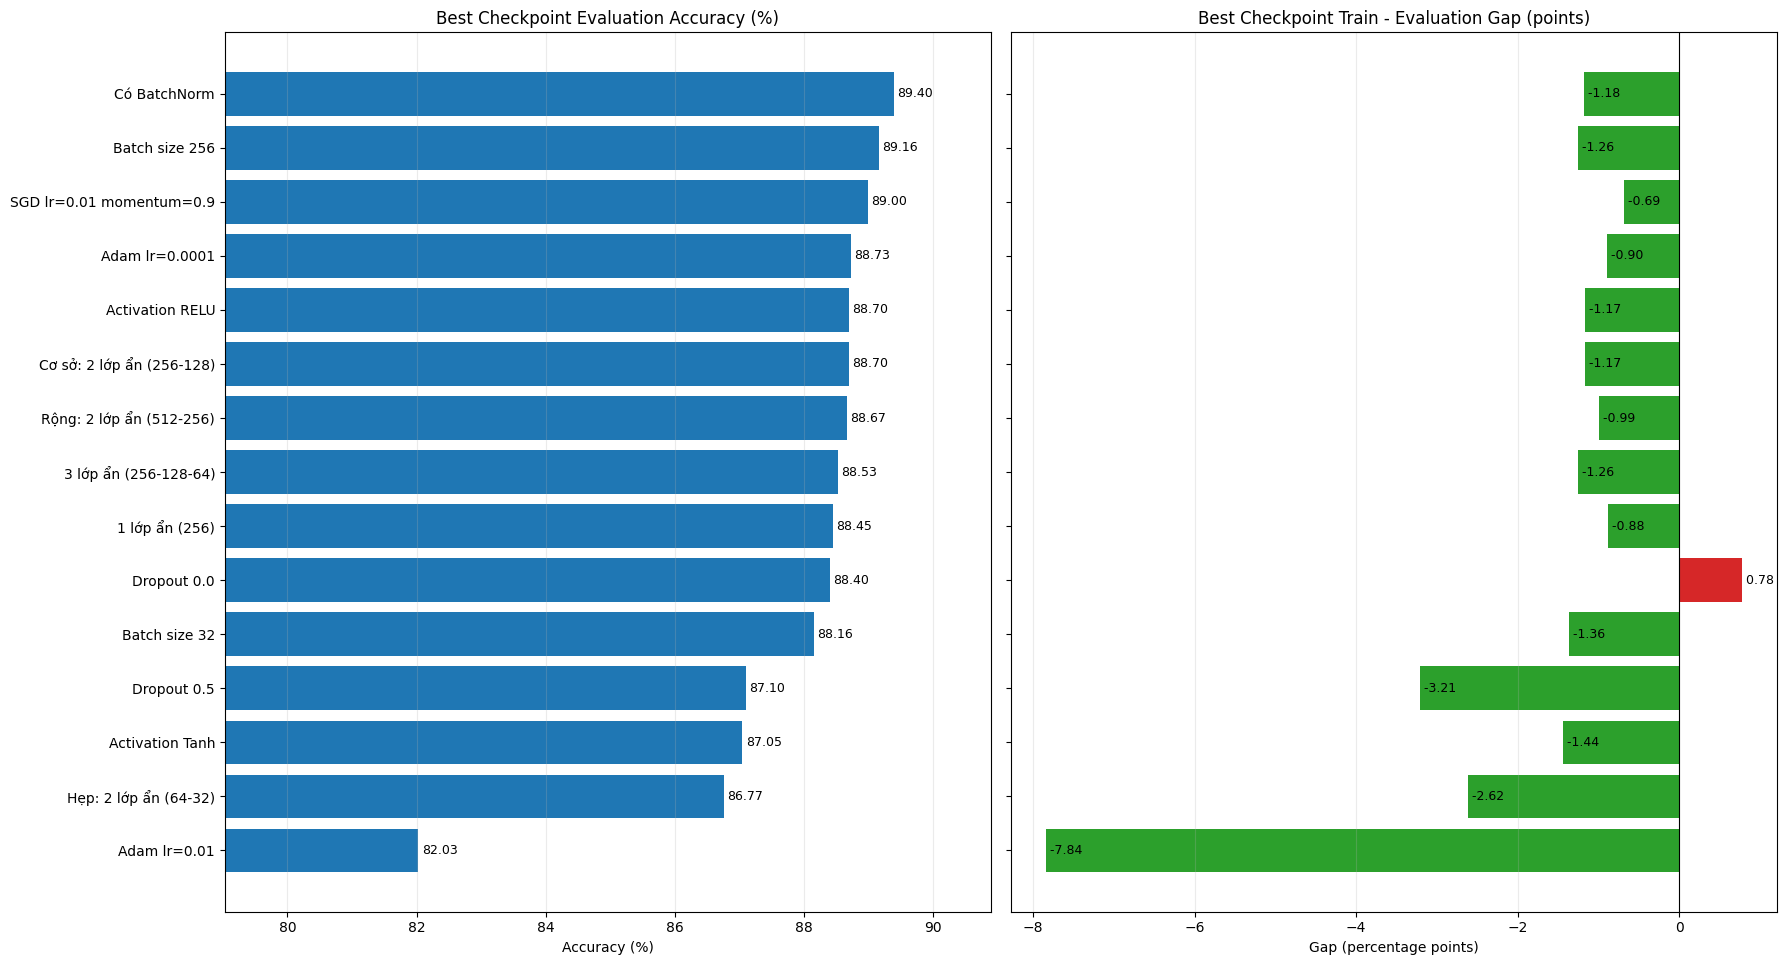

In [16]:
runner.plot_final_comparison()

Figure saved: ./artifacts/saved_figures\per_class\per_class_accuracy.png


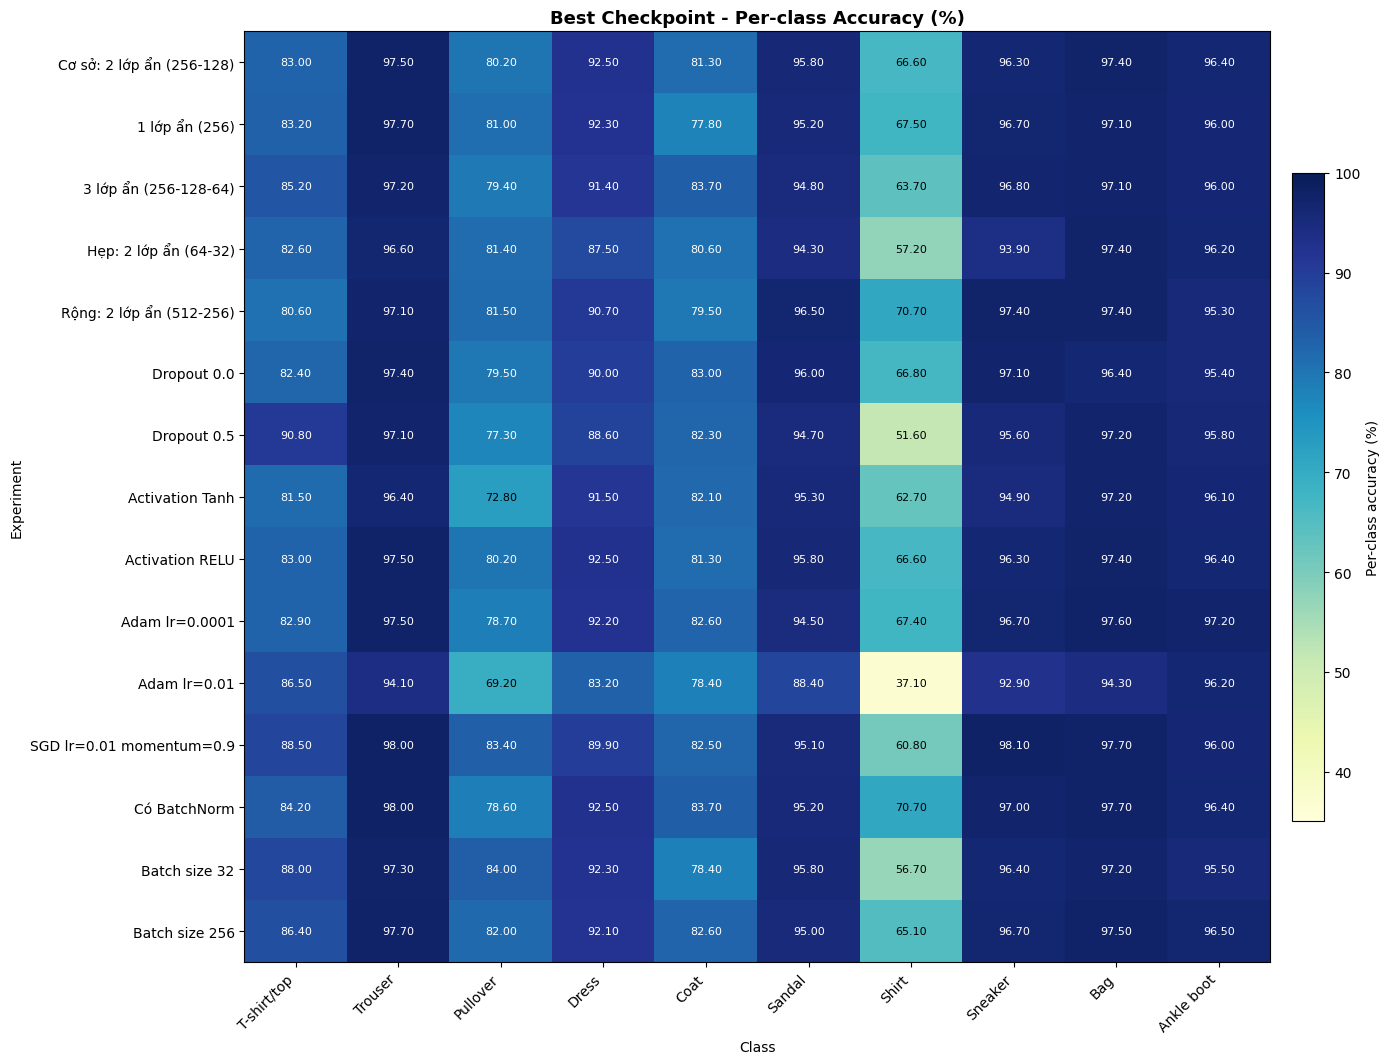

In [17]:
runner.plot_per_class_accuracy()

## 12. Detailed analysis
Full analysis of the baseline and of the experiment with the highest final accuracy: metrics table, learning curves, per-class report, confusion matrix and correct/wrong predictions. To look at another experiment, call `runner.show_detail("experiment name")`.

Thí nghiệm tốt nhất theo Accuracy cuối: Có BatchNorm
DETAILED ANALYSIS: Cơ sở: 2 lớp ẩn (256-128) (784 -> 256 -> 128 -> 10, Adam (lr=0.001))
Best Epoch: 34
Best Evaluation Loss: 0.312283
Best Checkpoint: ./saved_models\co_so_2_lop_an_256_128\best_checkpoint.pth
Last Checkpoint: ./saved_models\co_so_2_lop_an_256_128\last_checkpoint.pth


,Experiment,Accuracy (%),Macro Precision,Macro Recall,Macro F1-score
0,Cơ sở: 2 lớp ẩn (256-128),88.7,0.8862,0.887,0.8862


Figure saved: ./artifacts/saved_figures\detailed\co_so_2_lop_an_256_128_learning_curves.png


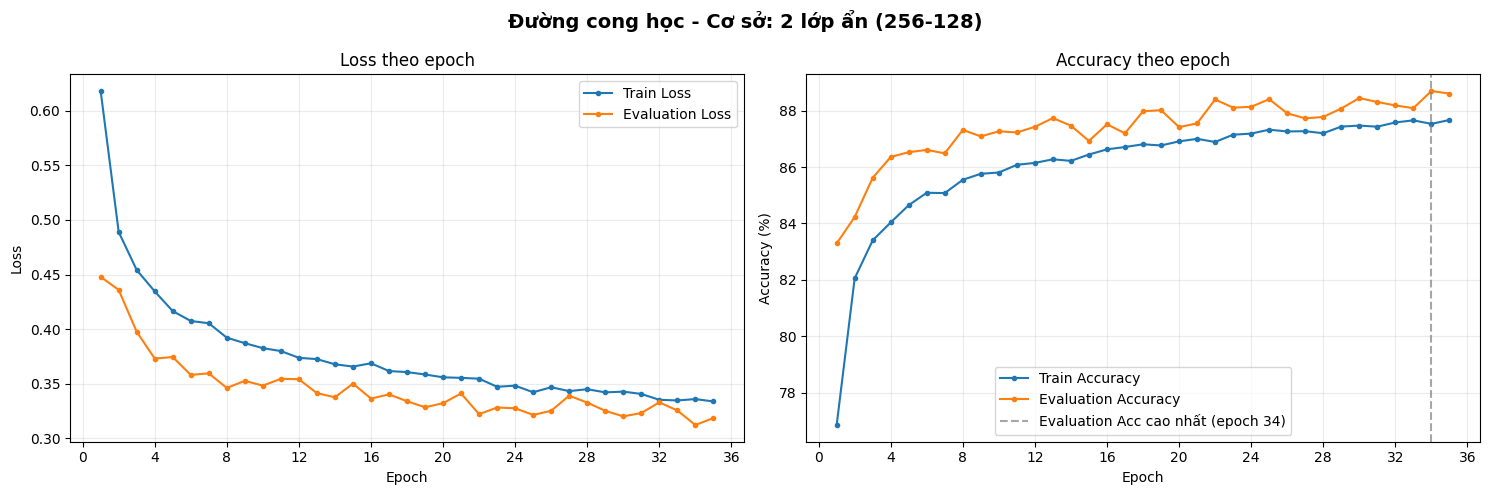

Per-class classification report (BEST checkpoint):
              precision    recall  f1-score   support

 T-shirt/top     0.8478    0.8300    0.8388      1000
     Trouser     0.9868    0.9750    0.9809      1000
    Pullover     0.8085    0.8020    0.8052      1000
       Dress     0.8565    0.9250    0.8894      1000
        Coat     0.7787    0.8130    0.7955      1000
      Sandal     0.9756    0.9580    0.9667      1000
       Shirt     0.7384    0.6660    0.7003      1000
     Sneaker     0.9423    0.9630    0.9525      1000
         Bag     0.9721    0.9740    0.9730      1000
  Ankle boot     0.9554    0.9640    0.9597      1000

    accuracy                         0.8870     10000
   macro avg     0.8862    0.8870    0.8862     10000
weighted avg     0.8862    0.8870    0.8862     10000

Figure saved: ./artifacts/saved_figures\detailed\co_so_2_lop_an_256_128_confusion_matrix.png


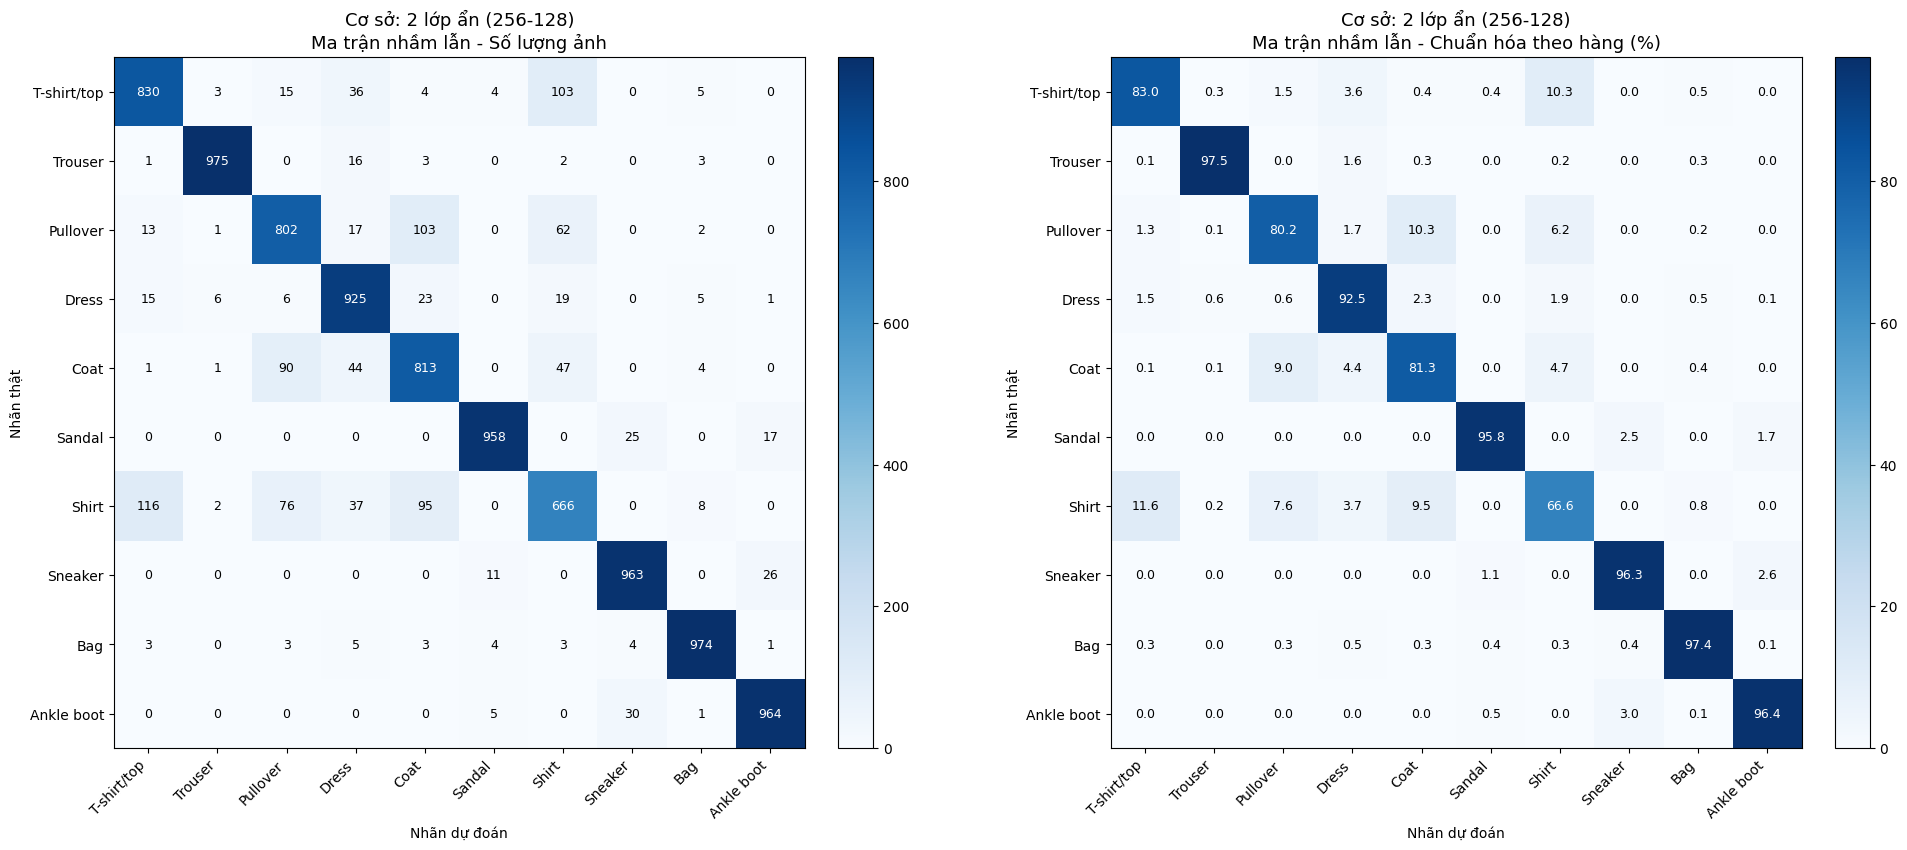

5 cặp nhầm lẫn nhiều nhất (nhãn thật -> dự đoán):
  Shirt -> T-shirt/top: 116 ảnh
  T-shirt/top -> Shirt: 103 ảnh
  Pullover -> Coat: 103 ảnh
  Shirt -> Coat: 95 ảnh
  Coat -> Pullover: 90 ảnh
Figure saved: ./artifacts/saved_figures\detailed\co_so_2_lop_an_256_128_sample_predictions.png


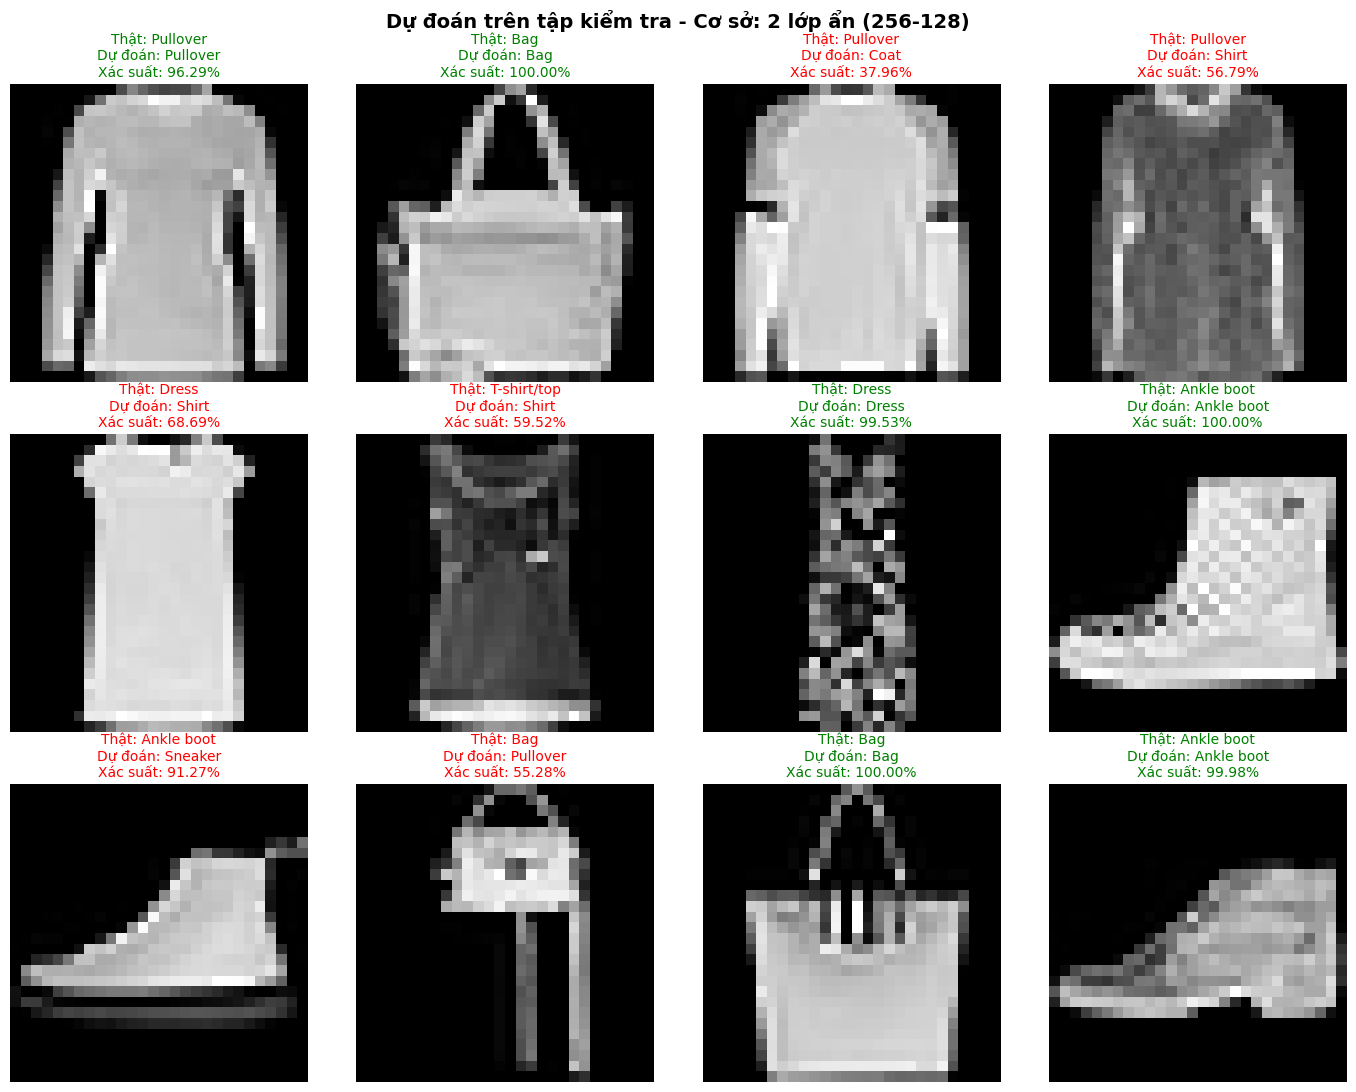

DETAILED ANALYSIS: Có BatchNorm (784 -> 256 -> 128 -> 10, Adam (lr=0.001))
Best Epoch: 34
Best Evaluation Loss: 0.289237
Best Checkpoint: ./saved_models\co_batchnorm\best_checkpoint.pth
Last Checkpoint: ./saved_models\co_batchnorm\last_checkpoint.pth


,Experiment,Accuracy (%),Macro Precision,Macro Recall,Macro F1-score
0,Có BatchNorm,89.4,0.8941,0.894,0.8937


Figure saved: ./artifacts/saved_figures\detailed\co_batchnorm_learning_curves.png


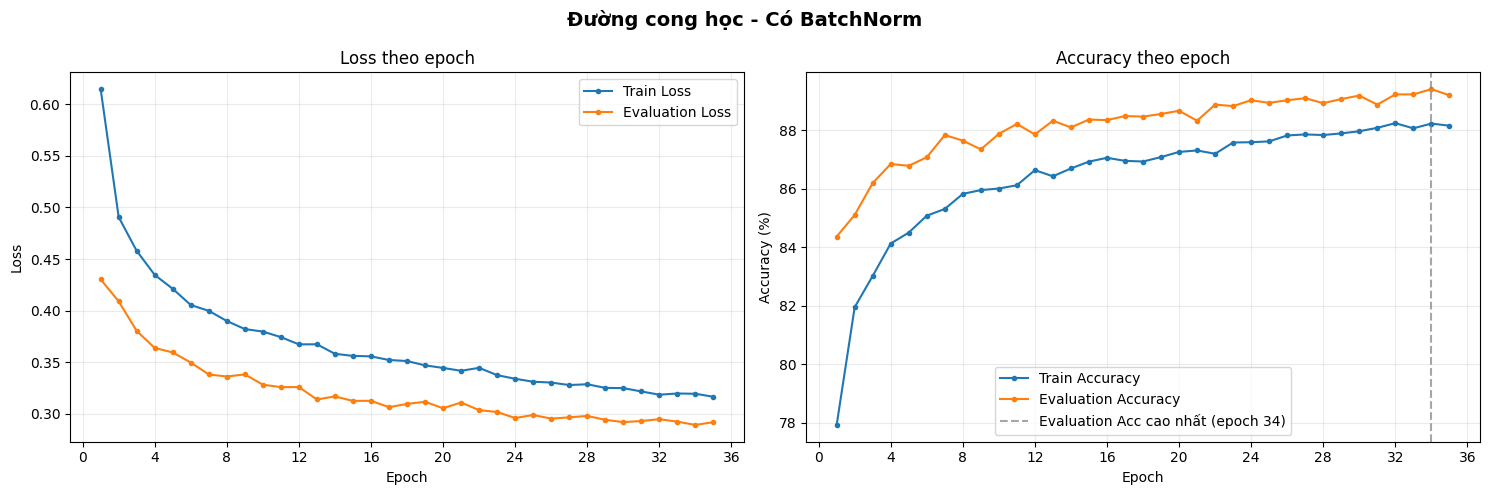

Per-class classification report (BEST checkpoint):
              precision    recall  f1-score   support

 T-shirt/top     0.8488    0.8420    0.8454      1000
     Trouser     0.9879    0.9800    0.9839      1000
    Pullover     0.8433    0.7860    0.8137      1000
       Dress     0.8685    0.9250    0.8959      1000
        Coat     0.8079    0.8370    0.8222      1000
      Sandal     0.9896    0.9520    0.9704      1000
       Shirt     0.7214    0.7070    0.7141      1000
     Sneaker     0.9300    0.9700    0.9496      1000
         Bag     0.9799    0.9770    0.9785      1000
  Ankle boot     0.9630    0.9640    0.9635      1000

    accuracy                         0.8940     10000
   macro avg     0.8941    0.8940    0.8937     10000
weighted avg     0.8941    0.8940    0.8937     10000

Figure saved: ./artifacts/saved_figures\detailed\co_batchnorm_confusion_matrix.png


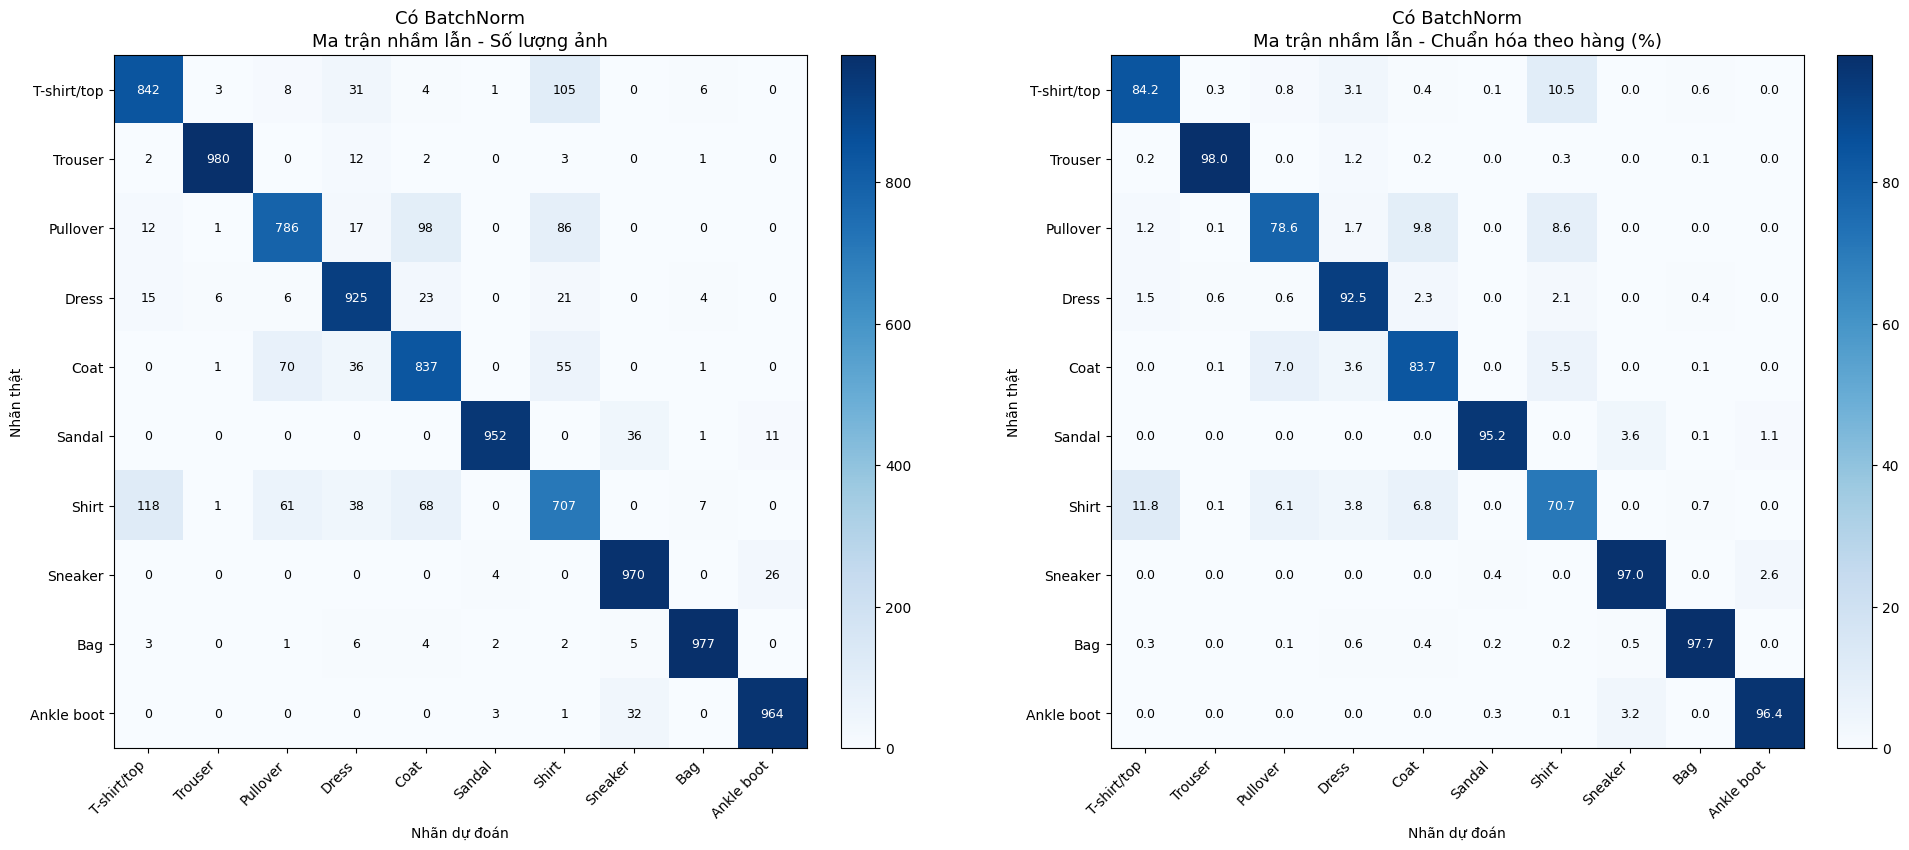

5 cặp nhầm lẫn nhiều nhất (nhãn thật -> dự đoán):
  Shirt -> T-shirt/top: 118 ảnh
  T-shirt/top -> Shirt: 105 ảnh
  Pullover -> Coat: 98 ảnh
  Pullover -> Shirt: 86 ảnh
  Coat -> Pullover: 70 ảnh
Figure saved: ./artifacts/saved_figures\detailed\co_batchnorm_sample_predictions.png


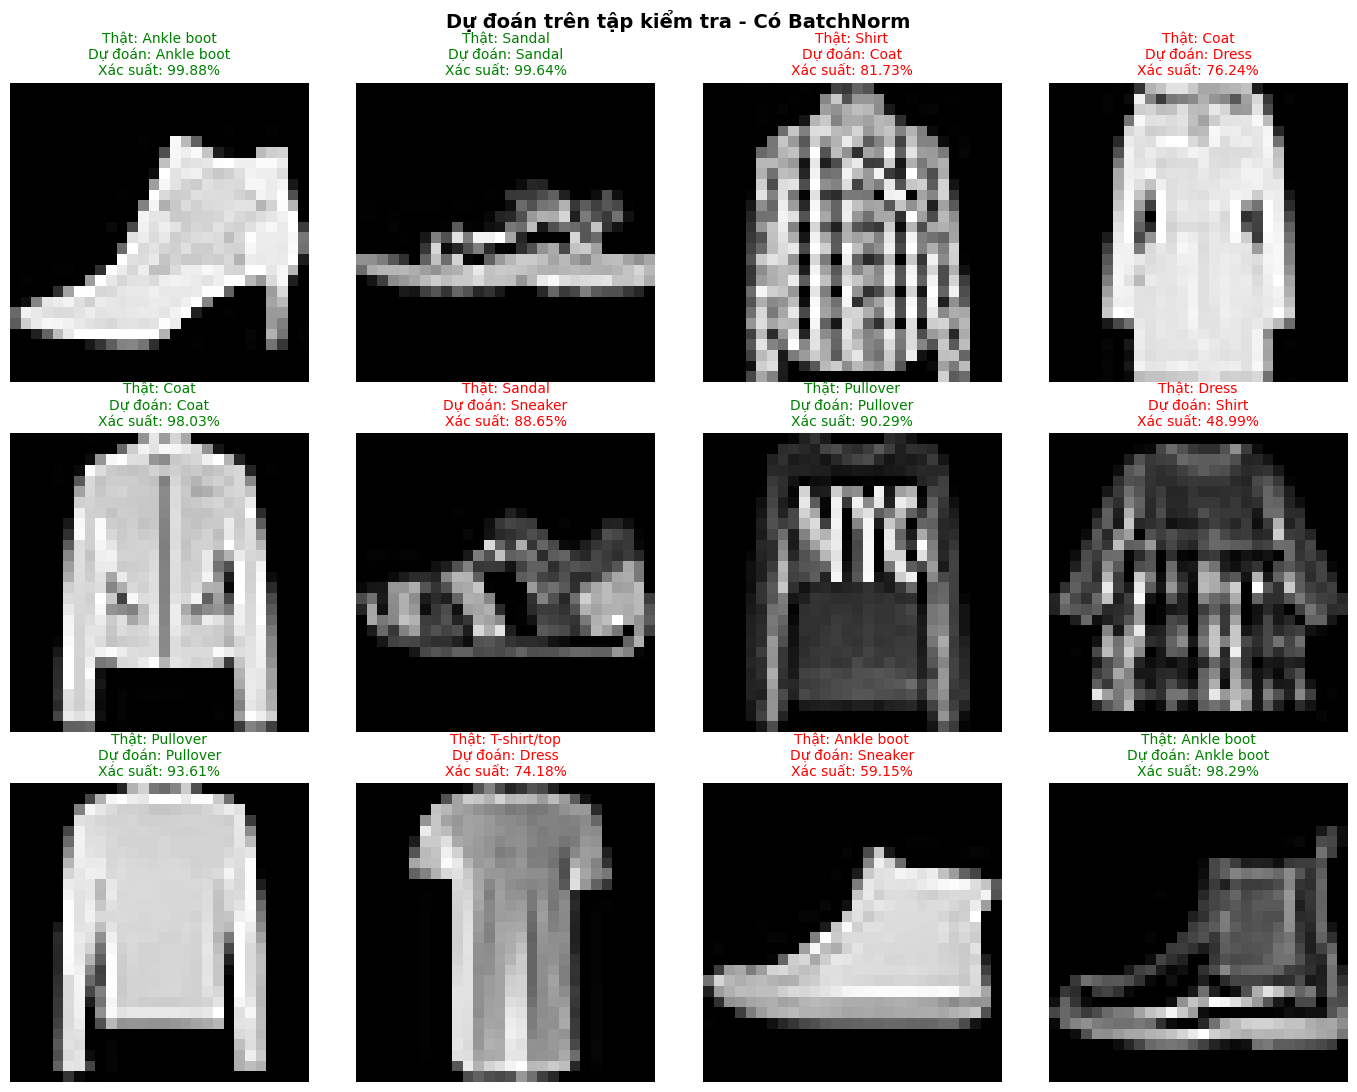

In [18]:
best_name = runner.best_name()
print("Thí nghiệm tốt nhất theo Accuracy cuối:", best_name)

runner.show_detail(BASELINE)
if best_name != BASELINE:
    runner.show_detail(best_name)


Inference benchmark | device: cuda | checkpoint: BEST | batch 256 | warmup 10 | runs 50
  Cơ sở: 2 lớp ẩn (256-128)         0.848 ms/batch |      301,949 images/s
  1 lớp ẩn (256)                    0.996 ms/batch |      257,100 images/s
  3 lớp ẩn (256-128-64)             0.726 ms/batch |      352,448 images/s
  Hẹp: 2 lớp ẩn (64-32)             0.439 ms/batch |      583,183 images/s
  Rộng: 2 lớp ẩn (512-256)          1.072 ms/batch |      238,829 images/s
  Dropout 0.0                       0.608 ms/batch |      420,835 images/s
  Dropout 0.5                       0.637 ms/batch |      401,678 images/s
  Activation Tanh                   0.579 ms/batch |      442,232 images/s
  Activation RELU                   0.588 ms/batch |      435,094 images/s
  Adam lr=0.0001                    0.582 ms/batch |      439,996 images/s
  Adam lr=0.01                      0.557 ms/batch |      459,231 images/s
  SGD lr=0.01 momentum=0.9          0.649 ms/batch |      394,505 images/s
  Có BatchN

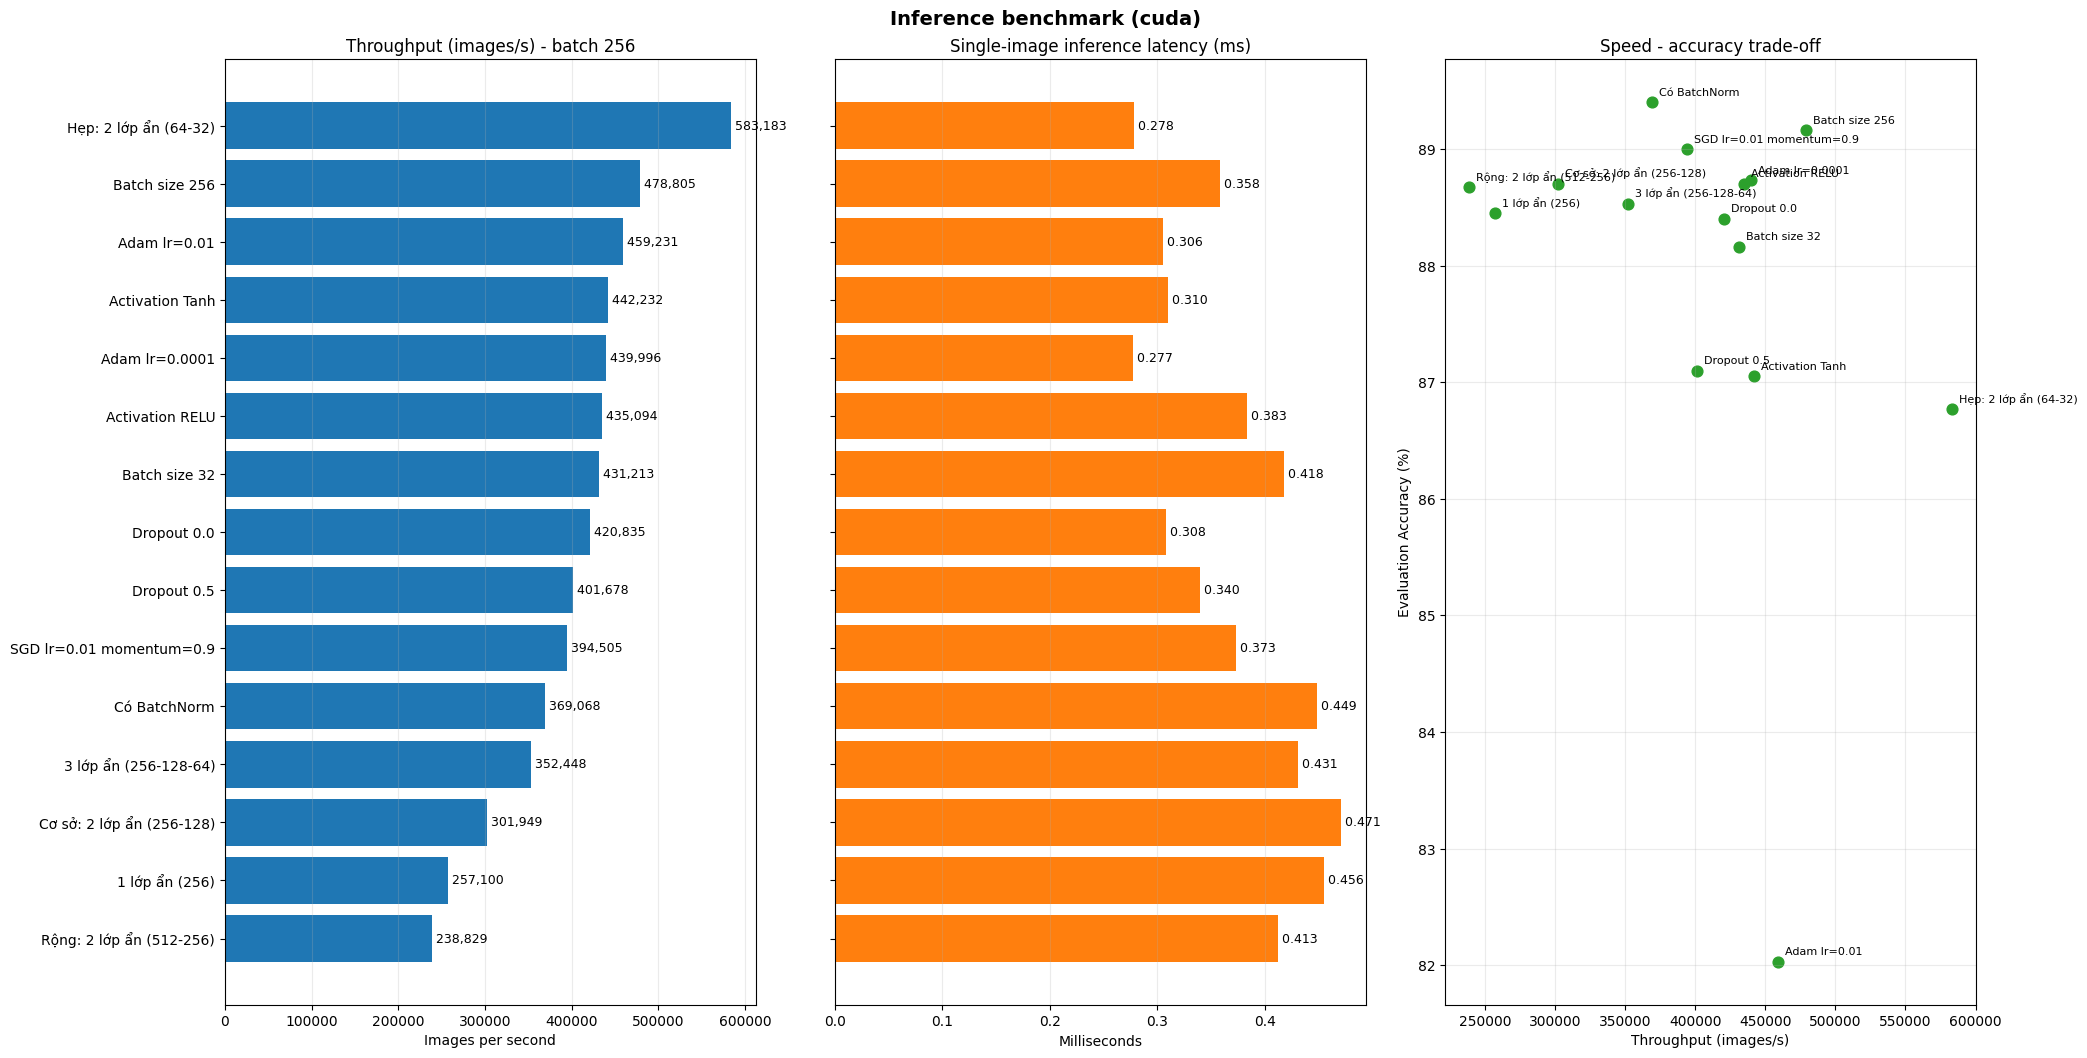

,Experiment,Group,Architecture,Parameters,Batch 256 (ms),Batch 256 Std (ms),Throughput (images/s),ms/image (batch),Single-Image Latency Mean (ms),Single-Image Latency P95 (ms),Model Size (MB),CPU RAM Peak (MB),GPU Model (MB),GPU Peak (MB),Evaluation Acc (%)
0,Hẹp: 2 lớp ẩn (64-32),2. Độ rộng lớp ẩn,784 -> 64 -> 32 -> 10,52650,0.438970,0.071193,583183.361007,0.001715,0.278070,0.374145,0.200844,0.019531,0.202148,1.295898,86.77
1,Batch size 256,7. Batch size,784 -> 256 -> 128 -> 10,235146,0.534664,0.052142,478805.380700,0.002089,0.358446,0.541225,0.897011,0.019531,0.897461,3.592773,89.16
2,Adam lr=0.01,5. Bộ tối ưu & learning rate,784 -> 256 -> 128 -> 10,235146,0.557454,0.043983,459230.716847,0.002178,0.305774,0.374255,0.897011,0.019531,0.897461,3.592773,82.03
3,Activation Tanh,4. Hàm kích hoạt,784 -> 256 -> 128 -> 10,235146,0.578882,0.080581,442231.749854,0.002261,0.309642,0.439210,0.897011,0.019531,0.897461,3.592773,87.05
4,Adam lr=0.0001,5. Bộ tối ưu & learning rate,784 -> 256 -> 128 -> 10,235146,0.581824,0.075469,439995.600016,0.002273,0.277190,0.326580,0.897011,0.019531,0.897461,3.592773,88.73
5,Activation RELU,4. Hàm kích hoạt,784 -> 256 -> 128 -> 10,235146,0.588378,0.093232,435094.446119,0.002298,0.383352,0.469025,0.897011,0.019531,0.897461,3.592773,88.70
6,Batch size 32,7. Batch size,784 -> 256 -> 128 -> 10,235146,0.593674,0.274746,431213.090190,0.002319,0.417730,0.669965,0.897011,0.023438,0.897461,3.592773,88.16
7,Dropout 0.0,3. Dropout,784 -> 256 -> 128 -> 10,235146,0.608314,0.071206,420835.292261,0.002376,0.308216,0.402755,0.897011,0.019531,0.897461,3.592773,88.40
8,Dropout 0.5,3. Dropout,784 -> 256 -> 128 -> 10,235146,0.637326,0.107229,401678.261899,0.002490,0.339918,0.571125,0.897011,0.019531,0.897461,3.592773,87.10
9,SGD lr=0.01 momentum=0.9,5. Bộ tối ưu & learning rate,784 -> 256 -> 128 -> 10,235146,0.648914,0.103730,394505.281190,0.002535,0.373172,0.628925,0.897011,0.023438,0.897461,2.692383,89.00


In [39]:
runner.benchmark_inference()

## 13. Saving and reloading models
The weights of every experiment were saved to `saved_models/` right after training. To reload, an `MLP` is first rebuilt from the experiment's own config and then the weights are loaded. The check below predicts on the evaluation set again and compares the accuracy.

In [20]:
runner.verify_saved_model(best_name)
print()
display(pd.DataFrame({
    "Thí nghiệm": list(runner.results),
    "File trọng số": [r.model_path for r in runner.results.values()]
}))


Checkpoint loaded successfully.
Experiment : Có BatchNorm
Type       : BEST
Path       : ./saved_models\co_batchnorm\best_checkpoint.pth
Epoch      : 34
Best Loss  : 0.289237

VERIFY BEST CHECKPOINT
Experiment         : Có BatchNorm
Reloaded Accuracy  : 89.4000%
Expected Accuracy  : 89.4000%
Difference         : 0.00000000 percentage points
STATUS: VERIFIED SUCCESSFULLY



,Thí nghiệm,File trọng số
0,Cơ sở: 2 lớp ẩn (256-128),./saved_models\co_so_2_lop_an_256_128\best_che...
1,1 lớp ẩn (256),./saved_models\1_lop_an_256\best_checkpoint.pth
2,3 lớp ẩn (256-128-64),./saved_models\3_lop_an_256_128_64\best_checkp...
3,Hẹp: 2 lớp ẩn (64-32),./saved_models\hep_2_lop_an_64_32\best_checkpo...
4,Rộng: 2 lớp ẩn (512-256),./saved_models\rong_2_lop_an_512_256\best_chec...
5,Dropout 0.0,./saved_models\dropout_0_0\best_checkpoint.pth
6,Dropout 0.5,./saved_models\dropout_0_5\best_checkpoint.pth
7,Activation Tanh,./saved_models\activation_tanh\best_checkpoint...
8,Activation RELU,./saved_models\activation_relu\best_checkpoint...
9,Adam lr=0.0001,./saved_models\adam_lr_0_0001\best_checkpoint.pth


In [21]:
# Replace "Baseline" with your BASELINE constant if its value differs.


configs = [

    # ---- Group 1: Number of hidden layers ----
    # 1. Baseline configuration
    ExperimentConfig(BASELINE, "1. Số lớp ẩn"),

    # 2. One hidden layer with 256 neurons
    ExperimentConfig("1 lớp ẩn (256)", "1. Số lớp ẩn",
                     hidden_sizes=(256,)),

    # 3. Three hidden layers with 256, 128, and 64 neurons
    ExperimentConfig("3 lớp ẩn (256-128-64)", "1. Số lớp ẩn",
                     hidden_sizes=(256, 128, 64)),

    # ---- Group 2: Hidden layer width ----
    # 4. Narrow hidden layers: 64 and 32 neurons
    ExperimentConfig("Hẹp: 2 lớp ẩn (64-32)", "2. Độ rộng lớp ẩn",
                     hidden_sizes=(64, 32)),

    # 5. Wide hidden layers: 512 and 256 neurons
    ExperimentConfig("Rộng: 2 lớp ẩn (512-256)", "2. Độ rộng lớp ẩn",
                     hidden_sizes=(512, 256)),

    # ---- Group 3: Dropout ----
    # 6. Disable dropout
    ExperimentConfig("Dropout 0.0", "3. Dropout", dropout=0.0),

    # 7. Set dropout rate to 0.5
    ExperimentConfig("Dropout 0.5", "3. Dropout", dropout=0.5),

    # ---- Group 4: Activation function ----
    # 8. Use Tanh activation function
    ExperimentConfig("Activation Tanh", "4. Hàm kích hoạt",
                     activation="tanh"),

    # 9. Use ReLU activation function
    ExperimentConfig("Activation RELU", "4. Hàm kích hoạt",
                     activation="relu"),

    # ---- Group 5: Optimizer and learning rate ----
    # 10. Adam optimizer with learning rate 0.0001
    ExperimentConfig("Adam lr=0.0001", "5. Bộ tối ưu & learning rate",
                     lr=1e-4),

    # 11. Adam optimizer with learning rate 0.01
    ExperimentConfig("Adam lr=0.01", "5. Bộ tối ưu & learning rate",
                     lr=1e-2),

    # 12. SGD optimizer with learning rate 0.01 and momentum 0.9
    ExperimentConfig("SGD lr=0.01 momentum=0.9",
                     "5. Bộ tối ưu & learning rate",
                     optimizer="sgd", lr=1e-2, momentum=0.9),

    # ---- Group 6: Batch normalization ----
    # 13. Enable batch normalization
    ExperimentConfig("Có BatchNorm", "6. BatchNorm", batch_norm=True),

    # ---- Group 7: Batch size ----
    # 14. Set batch size to 32
    ExperimentConfig("Batch size 32", "7. Batch size", batch_size=32),

    # 15. Set batch size to 256
    ExperimentConfig("Batch size 256", "7. Batch size", batch_size=256),
]

# Verify that the total number of experiments is 15
assert len(configs) == 15

Loaded epoch 34, best loss 0.335842


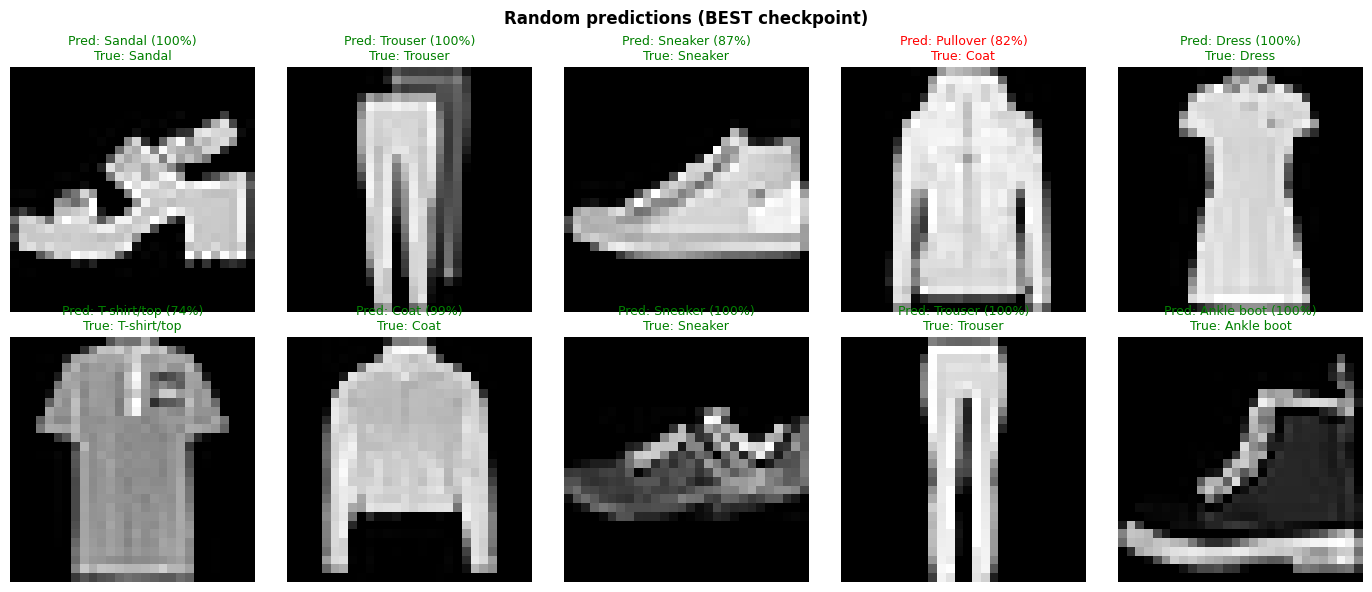

In [22]:
import os 
import random
# 1. Recreate the model with the SAME config used in training
config = configs[1]  # baseline config

model = MLP(config).to(DEVICE)

SAVE_DIR = "./saved_models"   # same as ExperimentRunner(save_dir=...)

# Build the checkpoint path from the experiment name
path = os.path.join(
    SAVE_DIR,
    slugify(config.name),
    "best_checkpoint.pth"              # or "last_checkpoint.pth"
)

if not os.path.isfile(path):
    raise FileNotFoundError(f"Checkpoint not found: {path}")
checkpoint = torch.load(path, map_location=DEVICE, weights_only=True)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print(f"Loaded epoch {checkpoint['epoch']}, "
      f"best loss {checkpoint['best_loss']:.6f}")

# 3. Pick 10 random images from the evaluation set
dataset = evaluation_loader.dataset

indices = random.sample(range(len(dataset)), 10)

images = torch.stack([dataset[i][0] for i in indices])
labels = torch.tensor([int(dataset[i][1]) for i in indices])

# 4. Predict
with torch.no_grad():
    probs = torch.softmax(model(images.to(DEVICE)), dim=1).cpu()

confidence, preds = probs.max(dim=1)

# 5. Show the results
class_names = evaluator.class_names

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for ax, img, true, pred, conf in zip(
    axes.ravel(), images, labels, preds, confidence
):
    ax.imshow(img.reshape(28, 28), cmap="gray")
    ax.axis("off")

    correct = true == pred

    ax.set_title(
        f"Pred: {class_names[pred]} ({conf:.0%})\n"
        f"True: {class_names[true]}",
        fontsize=9,
        color="green" if correct else "red",
    )

fig.suptitle("Random predictions (BEST checkpoint)", fontweight="bold")
fig.tight_layout()
plt.show()

## 14. Conclusions
The cell below collects the real numbers from your run: the best experiment of each group compared with the baseline, the experiment with the strongest sign of overfitting, and the hardest/easiest class. Use these numbers when writing the report.

In [33]:
runner.print_conclusions()

Baseline model 'Cơ sở: 2 lớp ẩn (256-128)': Best Accuracy 88.70%, Best Evaluation Loss 0.312283, Macro F1 0.8862.

Group 1. Số lớp ẩn:
  - Highest: 3 lớp ẩn (256-128-64) (88.53%, -0.17 pp vs baseline)
  - Lowest: 1 lớp ẩn (256) (88.45%, -0.25 pp vs baseline)
Group 2. Độ rộng lớp ẩn:
  - Highest: Rộng: 2 lớp ẩn (512-256) (88.67%, -0.03 pp vs baseline)
  - Lowest: Hẹp: 2 lớp ẩn (64-32) (86.77%, -1.93 pp vs baseline)
Group 3. Dropout:
  - Highest: Dropout 0.0 (88.40%, -0.30 pp vs baseline)
  - Lowest: Dropout 0.5 (87.10%, -1.60 pp vs baseline)
Group 4. Hàm kích hoạt:
  - Highest: Activation RELU (88.70%, +0.00 pp vs baseline)
  - Lowest: Activation Tanh (87.05%, -1.65 pp vs baseline)
Group 5. Bộ tối ưu & learning rate:
  - Highest: SGD lr=0.01 momentum=0.9 (89.00%, +0.30 pp vs baseline)
  - Lowest: Adam lr=0.01 (82.03%, -6.67 pp vs baseline)
Group 6. BatchNorm:
  - Có BatchNorm: 89.40% (+0.70 pp vs baseline)
Group 7. Batch size:
  - Highest: Batch size 256 (89.16%, +0.46 pp vs baseline)
 

## 15. Create PDF report

Create PDF general report

In [32]:
runner.create_report()

Figure saved: e:\Tài liệu học\2026-2027\học sâu ơi là sâu\lab1\Lab1_FashionMNIST_MLP_OOP\experiment_outputs\figures\group_curves\group_curves_1_so_lop_an.png
Figure saved: e:\Tài liệu học\2026-2027\học sâu ơi là sâu\lab1\Lab1_FashionMNIST_MLP_OOP\experiment_outputs\figures\group_curves\group_curves_2_do_rong_lop_an.png
Figure saved: e:\Tài liệu học\2026-2027\học sâu ơi là sâu\lab1\Lab1_FashionMNIST_MLP_OOP\experiment_outputs\figures\group_curves\group_curves_3_dropout.png
Figure saved: e:\Tài liệu học\2026-2027\học sâu ơi là sâu\lab1\Lab1_FashionMNIST_MLP_OOP\experiment_outputs\figures\group_curves\group_curves_4_ham_kich_hoat.png
Figure saved: e:\Tài liệu học\2026-2027\học sâu ơi là sâu\lab1\Lab1_FashionMNIST_MLP_OOP\experiment_outputs\figures\group_curves\group_curves_5_bo_toi_uu_learning_rate.png
Figure saved: e:\Tài liệu học\2026-2027\học sâu ơi là sâu\lab1\Lab1_FashionMNIST_MLP_OOP\experiment_outputs\figures\group_curves\group_curves_6_batchnorm.png
Figure saved: e:\Tài liệu học\2

'e:\\Tài liệu học\\2026-2027\\học sâu ơi là sâu\\lab1\\Lab1_FashionMNIST_MLP_OOP\\experiment_outputs\\report\\experiment_report.pdf'

### Guide for writing the discussion (fill in the numbers from your own results above)
- **Number of hidden layers and width:** does adding layers or neurons improve evaluation accuracy, and does it increase the Train – Evaluation gap?
- **Dropout:** does Dropout 0.0 reach high train accuracy but lower evaluation accuracy? Does Dropout 0.5 make the model learn slower or worse?
- **Activation function, BatchNorm:** how do these choices affect convergence speed and evaluation accuracy compared with ReLU without BatchNorm?
- **Trends:** for the effect of increasing the number of hidden layers, the learning rate or the batch size step by step, see the three sweep notebooks.
- **Optimizer, learning rate, batch size:** use the learning curves to see which settings converge fast, oscillate, or learn too slowly within 30 epochs.
- **Most confused classes:** classes with similar shapes (Shirt, T-shirt/top, Pullover, Coat) are usually the hardest to separate; compare with the mean images in section 4.4 and the heatmap in section 11.
- **Note:** results come from a single run with a single seed, so very small differences between experiments may be due to chance alone.